# DTC – V08682A – final runs for the DTC chapter

Everything needed for the chapter, in order:

1. **Pre-training** (40 epochs): reconstruction, losses, table of the losses.
2. **Scans with the Euclidean metric** (30 epochs), to justify the choices of the final runs:
   - $\gamma = 10, 100, 1000, 10000$ with 2 clusters;
   - 2, 3, 4 clusters with $\gamma = 1000$.
3. **Final runs, ACF / Euclidean / CID** (2 clusters, $\gamma = 1000$, `TRAINING_EPOCHS` epochs, from the **same** pre-trained TAE and seed):
   reconstruction, losses and table, separation in energy and A/E + rise time on training, validation and test set.
4. **Comparison** of the three metrics, with A/E as reference.

All the plots go to `/storage/rasera/DeepTemporalClusteringForL200/finalplots` with no subfolders: the file names start with the
run they belong to (`pretrain_...`, `scan_eucl_gamma1000_...`, `scan_eucl_3cl_...`, `acf_...`, `eucl_...`, `cid_...`).
Every table is shown here and also saved in the same folder as `.csv` and `.tex` (LaTeX `tabular`, ready for `\input`).

**If you re-run the import cell, re-run also the PARAMETERS cell**: importing `preliminary` / `DeepTemporalClustering` reloads `pf`
and resets `PLOT_DIR`, `TAG` and `PREFIX`.

In [61]:
import sys, os
sys.path.append(os.path.abspath('..'))     # common modules live in the main folder

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import importlib

import preliminary
importlib.reload(preliminary)
import plottingfunctions as pf
importlib.reload(pf)
import DeepTemporalClustering as DTC
importlib.reload(DTC)
import loadercreator
importlib.reload(loadercreator)

assert hasattr(pf, 'PREFIX'), "use the plottingfunctions.py with PREFIX (all the plots in one folder)"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("The device I'm using is:", device)
print("wfcleaningNEW in use:", preliminary.wfcleaning.__file__)

The device I'm using is: cuda
wfcleaningNEW in use: /storage/rasera/DeepTemporalClusteringForL200/wfcleaningNEW.py


# SANITY CHECKS

In [62]:
preliminary.sanity_check(use_charge=False)
preliminary.sanity_check(use_charge=True)
preliminary.sanity_check_dtc(use_charge=False)
preliminary.sanity_check_dtc(use_charge=True)

use_charge=False
  input shape:         (4, 1, 200)
  latent shape:        (4, 1, 20)  (atteso: (4, 1, 20))
  reconstructed shape: (4, 1, 200)  (atteso: (4, 1, 200))
  loss: 219005824.0000
  parametri senza gradiente: 0 (atteso: 0)
  logvar_obs.grad: [-2.1900718e+08]
  OK

use_charge=True
  input shape:         (4, 2, 200)
  latent shape:        (4, 1, 20)  (atteso: (4, 1, 20))
  reconstructed shape: (4, 2, 200)  (atteso: (4, 2, 200))
  loss: 217823552.0000
  parametri senza gradiente: 0 (atteso: 0)
  logvar_obs.grad: [-2.1631774e+08 -1.5080274e+06]
  OK

use_charge=False
  input shape:         (4, 1, 200)
  reconstructed shape: (4, 1, 200)  (atteso: (4, 1, 200))
  q shape:             (4, 2)  (atteso: (4, 2))
  q.sum(dim=1):        [1. 1. 1. 1.]  (atteso: tutti ~1.0)
  numero di tensori allenabili: 24  (atteso: > 0)
  loss: 206897840.0000
  parametri senza gradiente: 0 (atteso: 0)
  clusters.grad è None: False (atteso: False)
  OK

use_charge=True
  input shape:         (4, 2, 200)
  

# PARAMETERS

In [63]:
# ---------------- data / loaders ----------------
use_charge = False       # True: current + charge (2 channels) | False: current only
normalised = False       # True: corrente normalizzata a 1 evento per evento | False: corrente con ampiezza (A/E)
use_sigma  = False       # True: solo gli eventi nelle finestre SSE (DEP) e MSE (FEP) | False: tutta la finestra 1550-1650 keV
scale      = True        # True: corrente divisa per la mediana dei massimi del training set | False: nessuna scala

# ---------------- pre-training ----------------
PRETRAINING_EPOCHS = 50

# ---------------- choices of the final runs ----------------
N_CLUSTERS      = 2
GAMMA           = 1000
TRAINING_EPOCHS = 20           # final runs of the three metrics (still to be decided)
SEED            = 0            # same seed for every run: same KMeans start, same batch order

# ---------------- scans (Euclidean metric) ----------------
SCAN_METRIC   = 'eucl'
SCAN_EPOCHS   = 20
SCAN_GAMMAS   = [10, 100, 1000, 10000]      # with N_CLUSTERS clusters
SCAN_CLUSTERS = [2, 3, 4]                   # with GAMMA

# pf.TAG -> name of the metric in DTC (pf.TAG gives the color of the metric in the plots)
METRICS = {'acf': 'acf', 'eucl': 'euclidean', 'cid': 'cid'}
NAMES   = {'acf': 'ACF', 'eucl': 'Euclidean', 'cid': 'CID'}

# ---------------- output ----------------
pf.PLOT_DIR = "/storage/rasera/DeepTemporalClusteringForL200/finalplots"   # plots AND tables, no subfolders
pf.TAG, pf.PREFIX = '', ''
TABLE_DIR = pf.PLOT_DIR
OUT_DIR   = "finalmodels"                                                  # weights and bundles of the final runs
os.makedirs(pf.PLOT_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# PRELIMINARY
Data loading, cleaning and loaders creation.

Periods to process: ['p03', 'p04', 'p05', 'p06', 'p07', 'p08', 'p09']
Period p03: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p04: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p05: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p06: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p07: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p08: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p09: checkpoint loaded from /storage/rasera/clean_data_V08682A
Totale su 7 periodi: 349002 eventi (116985 dopo il taglio A/E)
Waveforms shape (all periods): (349002, 1400)
Energy shape (all periods): (349002,)
Amplitude vs Energy shape (all periods): (349002,)
Rise time shape (all periods): (349002,)
Waveforms shape after AoE cut (all periods): (116985, 1400)
Energy shape after AoE cut (all periods): (116985,)
Rise time shape after AoE cut (all periods): (116985,)
wfcleaningNEW in use: /storage/ras

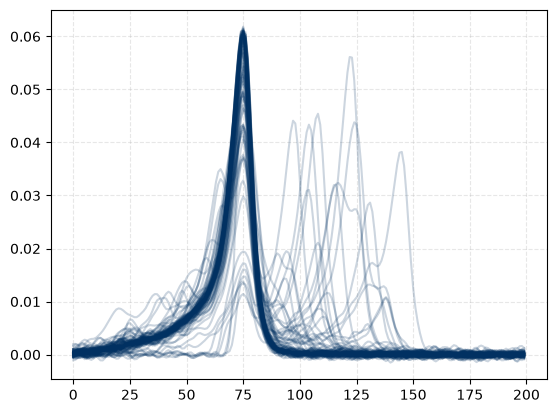

Charge aligned: (348999, 200)
Current aligned: (348999, 200)
Kept: 348999 | noise: 3 | edge: 0 | total: 349002
rise time (all events): 348999 events | NaN/inf: 0 | <= 0: 0
  mean rise time [ns]: 619.1 | median [ns]: 544.0
Charge AoE aligned: (116984, 200)
Current AoE aligned: (116984, 200)
Kept: 116984 | noise: 1 | edge: 0 | total: 116985
rise time (after A/E cut): 116984 events | NaN/inf: 0 | <= 0: 0
  mean rise time [ns]: 517.7 | median [ns]: 528.0
corrente: mediana su 50 punti 0.000456 | mediana su 10 punti 0.000314
carica: mediana su 50 punti 0.004501 | mediana su 10 punti 0.001448
use_charge: False | use_sigma: False | normalised: False | scale: True (scale factor = 0.05650758299488506) | scale_charge: False (charge scale factor = 1.0)
waves: (348999, 1, 200) | NaN/inf: 0
rumore corrente su questa scala (current_noise): 0.008069798057257726
rumore carica su questa scala (charge_noise):   0.004500837161356608
correlazione altezza picco - A/E: 0.9908282813347021
train: 279199 | val:

In [64]:
raw   = preliminary.load_data(chosen_detector="V08682A", e_min=1550, e_max=1650, output_dir="/storage/rasera/clean_data_V08682A")
clean = preliminary.clean_data(raw)
train_loader, validation_loader, all_loader, data = preliminary.create_loaders(clean, use_charge=use_charge, normalised=normalised, use_sigma=use_sigma, scale=scale)

### DEP and FEP windows
Gaussian fits on the clustered events, windows at $\pm 3\sigma$: used to find the SSE-like cluster of every run and in the tables.

In [65]:
energy = data['energy']     # same events, same order, as the cluster assignments (all_loader)

dep, _ = loadercreator.gaussian(energy, xmin=1587, xmax=1598)
fep, _ = loadercreator.gaussian(energy, xmin=1615, xmax=1626)
in_dep = np.abs(energy - dep[1]) <= 3 * dep[2]
in_fep = np.abs(energy - fep[1]) <= 3 * fep[2]

print(f"DEP: mu = {dep[1]:.2f} keV, sigma = {dep[2]:.2f} keV -> {in_dep.sum()} events in the window")
print(f"FEP: mu = {fep[1]:.2f} keV, sigma = {fep[2]:.2f} keV -> {in_fep.sum()} events in the window")

DEP: mu = 1592.40 keV, sigma = 2.10 keV -> 59254 events in the window
FEP: mu = 1620.34 keV, sigma = 2.33 keV -> 95364 events in the window


### Tables
Every table is shown and saved in `TABLE_DIR` as `.csv` and as a LaTeX `tabular` (`.tex`).

In [66]:
def _latex_escape(text):
    for a, b in (('\\', r'\textbackslash{}'), ('%', r'\%'), ('_', r'\_'), ('&', r'\&'), ('#', r'\#')):
        text = text.replace(a, b)
    return text


def save_table(df, name, decimals=2):
    """Show the table and save it as TABLE_DIR/name.csv and TABLE_DIR/name.tex."""
    display(df.round(decimals))
    df.to_csv(os.path.join(TABLE_DIR, name + '.csv'))
    fmt = lambda v: f"{v:.{decimals}f}" if isinstance(v, (float, np.floating)) else _latex_escape(str(v))
    header = [_latex_escape(str(df.index.name or ''))] + [_latex_escape(str(c)) for c in df.columns]
    lines = [r'\begin{tabular}{l' + 'r' * len(df.columns) + '}', r'\hline', ' & '.join(header) + r' \\', r'\hline']
    for idx, row in df.iterrows():
        lines.append(' & '.join([fmt(idx)] + [fmt(v) for v in row]) + r' \\')
    lines += [r'\hline', r'\end{tabular}']
    with open(os.path.join(TABLE_DIR, name + '.tex'), 'w') as fh:
        fh.write('\n'.join(lines) + '\n')
    print("saved:", os.path.join(TABLE_DIR, name + '.csv'), "|", name + '.tex')

# 1. PRE-TRAINING
Once, shared by every run of this notebook. Plots: `pretrain_reconstruction.pdf`, `pretrain_losses.pdf`.

initial sigma of the NLL: 0.00807
Pretraining on the device: cuda
[pretrain] epoch 1/50 - train: 862.2236  val: -544.9603
[pretrain] epoch 2/50 - train: -617.5209  val: -677.0284
[pretrain] epoch 3/50 - train: -708.7578  val: -735.1903
[pretrain] epoch 4/50 - train: -745.9618  val: -755.4594
[pretrain] epoch 5/50 - train: -758.7723  val: -761.6278
[pretrain] epoch 6/50 - train: -764.9618  val: -768.3399
[pretrain] epoch 7/50 - train: -769.6447  val: -772.2346
[pretrain] epoch 8/50 - train: -773.2210  val: -776.1803
[pretrain] epoch 9/50 - train: -776.0766  val: -778.3527
[pretrain] epoch 10/50 - train: -778.4382  val: -780.2478
[pretrain] epoch 11/50 - train: -780.5184  val: -782.6684
[pretrain] epoch 12/50 - train: -782.4867  val: -780.0785
[pretrain] epoch 13/50 - train: -784.2180  val: -786.7137
[pretrain] epoch 14/50 - train: -785.7321  val: -786.7025
[pretrain] epoch 15/50 - train: -787.1635  val: -788.8978
[pretrain] epoch 16/50 - train: -788.5136  val: -789.9221
[pretrain] epoch

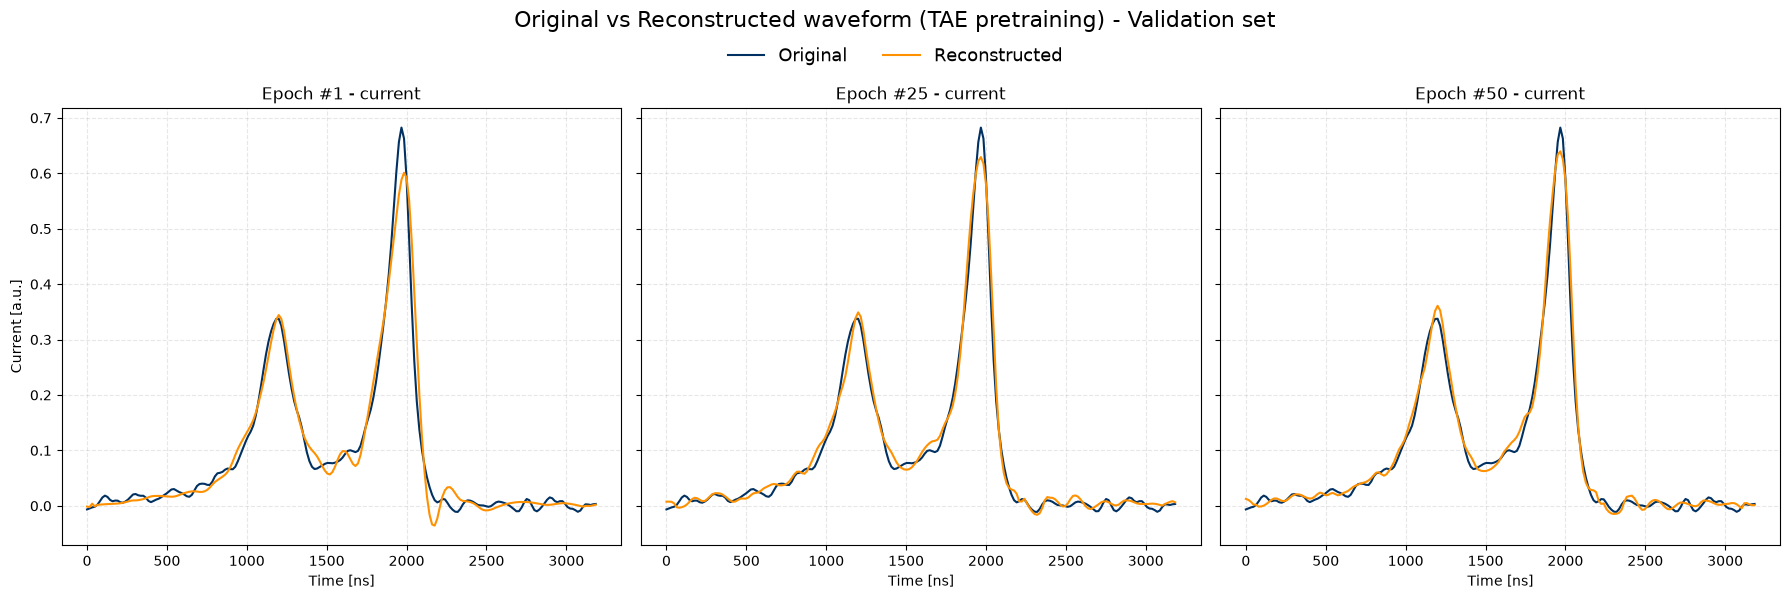

saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/tae_pretrained_50ep.pth


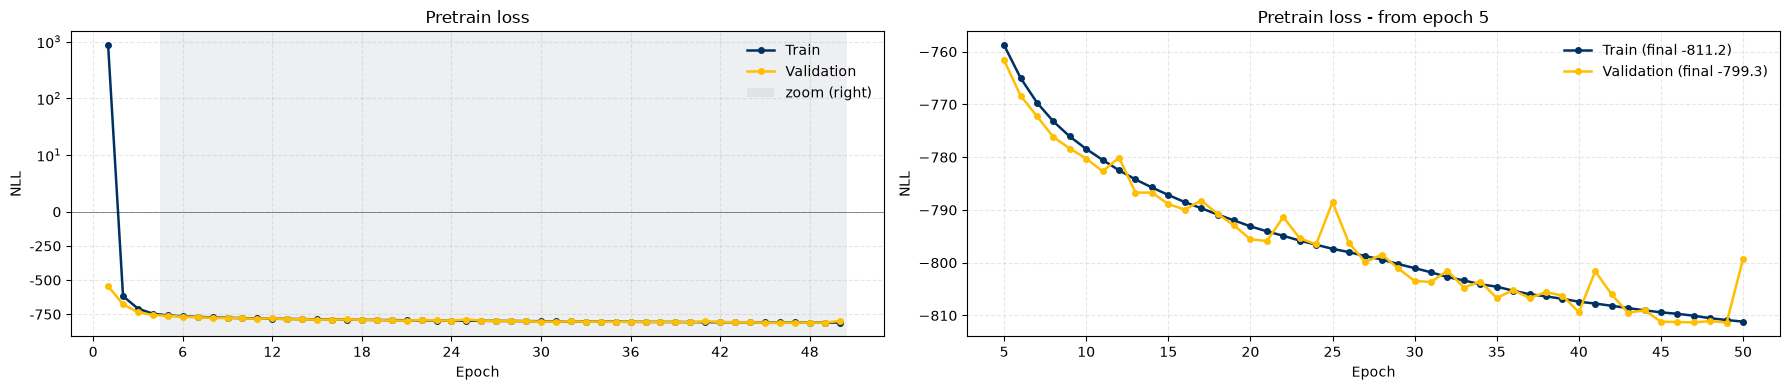

In [67]:
TAE_PATH = os.path.join(OUT_DIR, f"tae_pretrained_{PRETRAINING_EPOCHS}ep.pth")

torch.manual_seed(42)
dtc = DTC.DTC(input_length=data['waves'].shape[-1], pool_size=10, n_clusters=N_CLUSTERS, use_charge=use_charge)

# noise of the NLL initialised from the data (baseline of the training waveforms, on the scale fed to the network)
noise = np.median(np.std(data['waves'][data['idx_train'], 0, :20], axis=1))
with torch.no_grad():
    dtc.tae.logvar_obs.fill_(float(np.log(noise ** 2)))
print(f"initial sigma of the NLL: {noise:.5f}")

pf.TAG, pf.PREFIX = '', ''
pre_train_l, pre_val_l = DTC.pretrain(dtc.tae, train_loader, validation_loader, epochs=PRETRAINING_EPOCHS)

torch.save(dtc.tae.state_dict(), TAE_PATH)
print("saved:", os.path.abspath(TAE_PATH))

pf.plot_pretrain_losses(pre_train_l, pre_val_l)

#### Table: pre-training losses

In [68]:
pre_table = pd.DataFrame({'NLL train': pre_train_l, 'NLL validation': pre_val_l},
                         index=pd.Index(np.arange(1, len(pre_train_l) + 1), name='epoch'))
save_table(pre_table, 'table_pretrain_losses')

,NLL train,NLL validation
epoch,,
1,862.22,-544.96
2,-617.52,-677.03
3,-708.76,-735.19
4,-745.96,-755.46
5,-758.77,-761.63
6,-764.96,-768.34
7,-769.64,-772.23
8,-773.22,-776.18
9,-776.08,-778.35


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_pretrain_losses.csv | table_pretrain_losses.tex


# 2. DTC TRAINING – common functions
Every run reloads the **same** pre-trained TAE, freezes `logvar_obs`, initialises the clusters with KMeans and rewinds the shuffle
with the **same** seed: two runs differ only in what is changed on purpose (metric, $\gamma$, number of clusters).

In [69]:
def cluster_run(n_clusters, distance_metric, gamma, epochs, weights=TAE_PATH, seed=SEED):
    
    torch.manual_seed(seed)
    
    assert train_loader.generator is not None, \
        "train_loader va ricostruito con epoch_loader(..., seed=...) perché questo funzioni"
    train_loader.generator.manual_seed(seed)   # riavvolge lo shuffle: indipendente da quante corse ci sono state prima
    
    model = DTC.DTC(input_length=data['waves'].shape[-1], pool_size=10, n_clusters=n_clusters,
                    distance_metric=distance_metric, use_charge=use_charge)
    model.tae.load_state_dict(torch.load(weights, map_location="cpu", weights_only=True))
    model.tae.logvar_obs.requires_grad_(False)
    
    DTC.initialization_of_clusters_weights(model, train_loader, seed=seed)
    dev = next(model.parameters()).device
    y_init = DTC.cluster_assignments(model, all_loader, dev)
    
    model, tr, va, frac, chg = DTC.training(model, train_loader, validation_loader, epochs=epochs, gamma=gamma)
    y_after = DTC.cluster_assignments(model, all_loader, dev)
    
    print(f"[{distance_metric}, gamma={gamma}, {n_clusters} clusters] events that changed cluster with the training: "
          f"{(y_init != y_after).mean():.4f}")
    return dict(model=model, y_init=np.asarray(y_init), y=np.asarray(y_after), total_train=tr, total_val=va,
                gamma=gamma, n_clusters=n_clusters, metric=distance_metric)


def training_table(run):
    """Losses of every epoch of a DTC run."""
    h = run['model'].history
    frac = ['/'.join(f"{x:.2f}" for x in np.ravel(f)) for f in h['fractions']]
    return pd.DataFrame({'total train': run['total_train'], 'total validation': run['total_val'],
                         'NLL train': h['nll_train'], 'NLL validation': h['nll_val'],
                         'KL train': h['kl_train'], 'KL validation': h['kl_val'],
                         'changes [%]': 100 * np.asarray(h['changes']),
                         'events per cluster': frac},
                        index=pd.Index(np.arange(1, len(run['total_train']) + 1), name='epoch'))


def composition(y, n_clusters, mask=None):
    """Fraction of the events of every cluster, and fraction of the DEP / FEP events in every cluster."""
    m = np.ones(len(y), bool) if mask is None else np.zeros(len(y), bool)
    if mask is not None:
        m[mask] = True
    size = [float((y[m] == k).mean()) for k in range(n_clusters)]
    dep_f = [float((y[m & in_dep] == k).mean()) for k in range(n_clusters)]
    fep_f = [float((y[m & in_fep] == k).mean()) for k in range(n_clusters)]
    return size, dep_f, fep_f


def sse_like(y, n_clusters):
    """SSE-like cluster: the one with the largest (DEP fraction - FEP fraction), on all the events."""
    _, dep_f, fep_f = composition(y, n_clusters)
    return int(np.argmax(np.array(dep_f) - np.array(fep_f)))


def plot_energy_and_history(run, prefix, label):
    """Training history + clusters vs energy on the whole calibration dataset (used by the scans)."""
    pf.PREFIX = prefix
    k = run['n_clusters']
    pf.plot_training_history(run['model'].history, name=f"{k}cl_training_history")
    pf.plot_clusters_vs_energy(run['y'], energy, k, title=f"{pf._title(k, 'all', len(energy))} - {label}",
                               name=f"{k}cl_energy_all", colors=pf.cluster_colors(run['y'], energy, k))

# 2a. SCAN OF $\gamma$ (Euclidean, 30 epochs, 2 clusters)
For every $\gamma$: reconstruction after the training, training history, clusters vs energy on the whole calibration dataset
(files `scan_eucl_gamma<γ>_...`). Then one summary table.

$\gamma$ is chosen with **unsupervised** criteria (reconstruction not degraded, assignments that move away from KMeans and then
stabilise); the DEP/FEP columns are shown as a check, not used for the choice.

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.888 0.112]
[train] epoch 1/20 - train: -807.7887  val: -812.0271  events per cluster: [0.932 0.068]  changes: 0.0443
        NLL: -807.91   KL: 0.0119
[train] epoch 2/20 - train: -811.6145  val: -813.6728  events per cluster: [0.931 0.069]  changes: 0.0013
        NLL: -811.74   KL: 0.0125
[train] epoch 3/20 - train: -811.8443  val: -811.8801  events per cluster: [0.93 0.07]  changes: 0.0006
        NLL: -811.97   KL: 0.0125
[train] epoch 4/20 - train: -812.1493  val: -811.1419  events per cluster: [0.932 0.068]  changes: 0.0019
        NLL: -812.27   KL: 0.0125
[train] epoch 5/20 - train: -812.4042  val: -813.9277  events per cluster: [0.93 0.07]  changes: 0.0018
        NLL: -812.53   KL: 0.0125
[train] epoch 6/20 - train: -812.7730  val: -812.1598  events per cluster: [0.932 0.068]  changes: 0.0021
        N

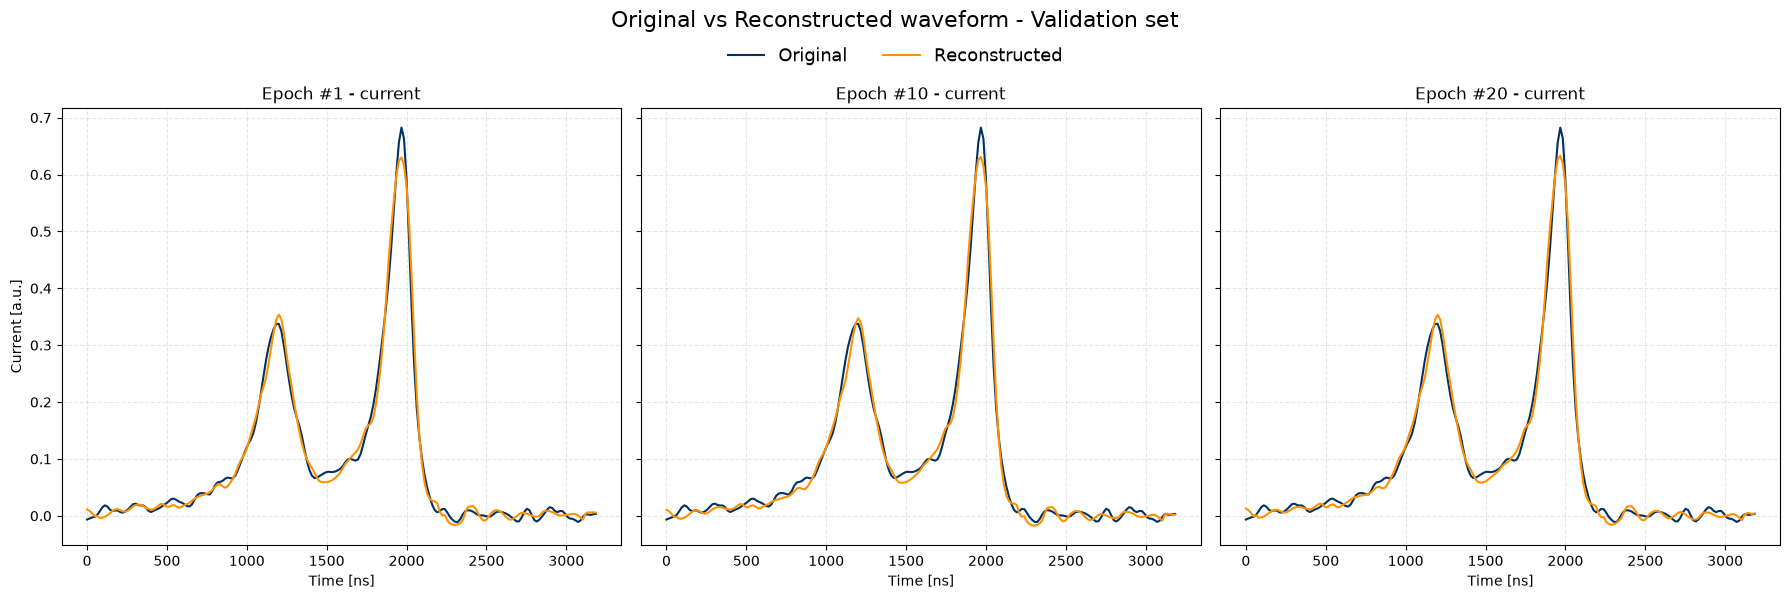

[euclidean, gamma=10, 2 clusters] events that changed cluster with the training: 0.0417


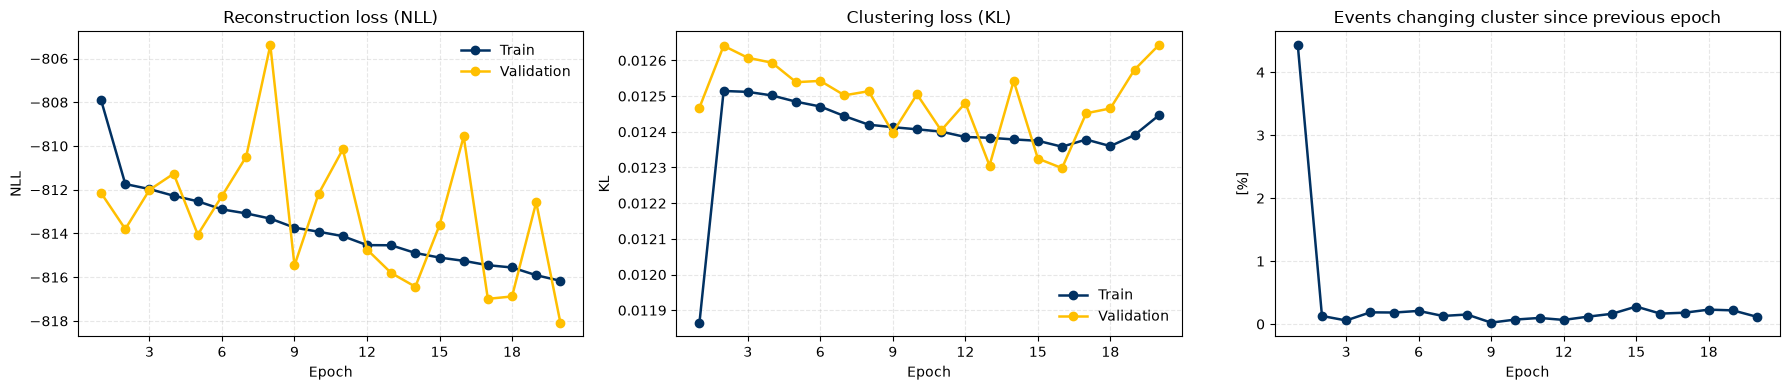

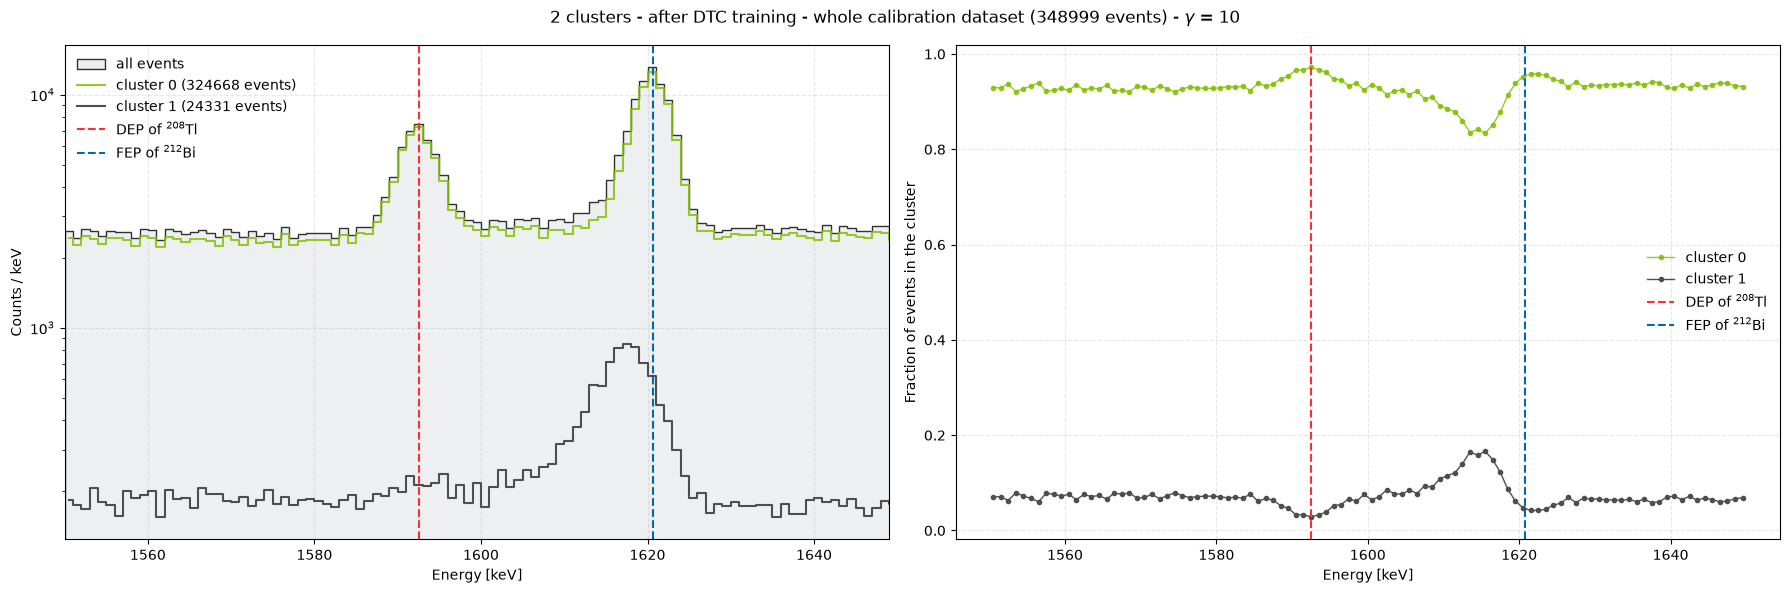

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.888 0.112]
[train] epoch 1/20 - train: -806.6576  val: -810.1735  events per cluster: [0.931 0.069]  changes: 0.0435
        NLL: -807.87   KL: 0.0122
[train] epoch 2/20 - train: -810.3652  val: -812.3084  events per cluster: [0.929 0.071]  changes: 0.0016
        NLL: -811.68   KL: 0.0132
[train] epoch 3/20 - train: -810.5185  val: -810.6997  events per cluster: [0.928 0.072]  changes: 0.0019
        NLL: -811.86   KL: 0.0134
[train] epoch 4/20 - train: -810.8228  val: -810.3062  events per cluster: [0.93 0.07]  changes: 0.0023
        NLL: -812.19   KL: 0.0136
[train] epoch 5/20 - train: -811.0308  val: -812.2904  events per cluster: [0.928 0.072]  changes: 0.0023
        NLL: -812.41   KL: 0.0138
[train] epoch 6/20 - train: -811.3256  val: -811.1021  events per cluster: [0.93 0.07]  changes: 0.0021
        N

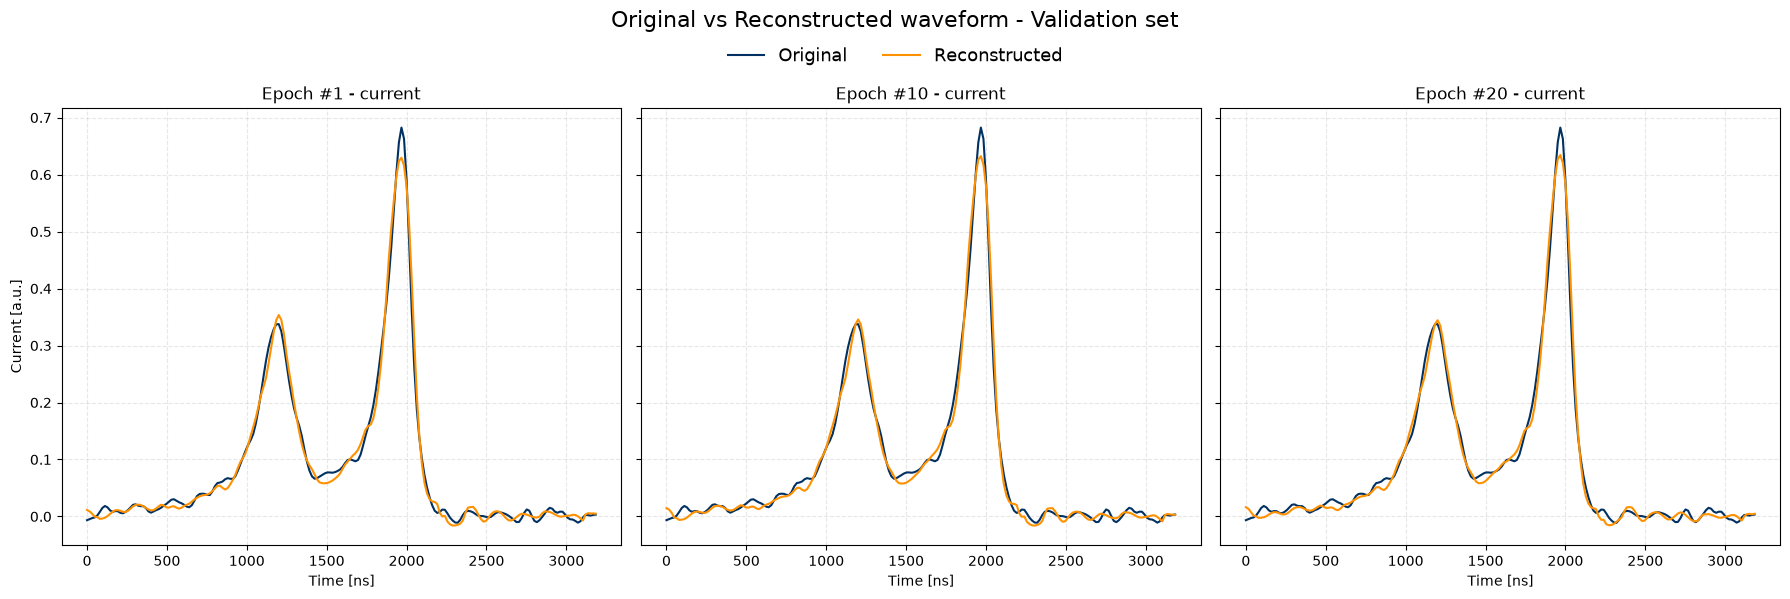

[euclidean, gamma=100, 2 clusters] events that changed cluster with the training: 0.0323


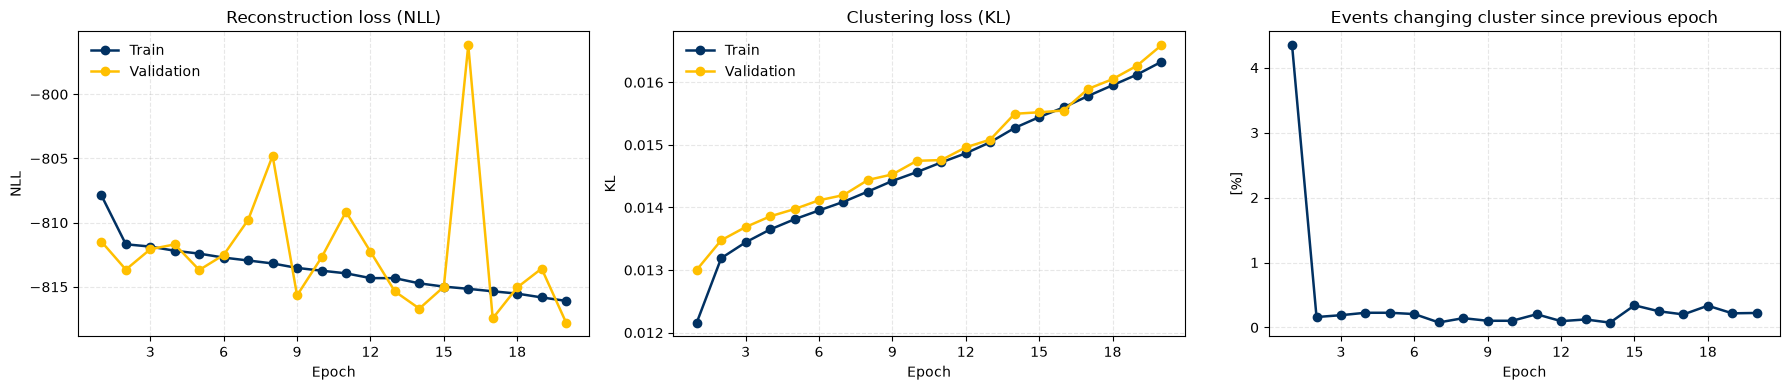

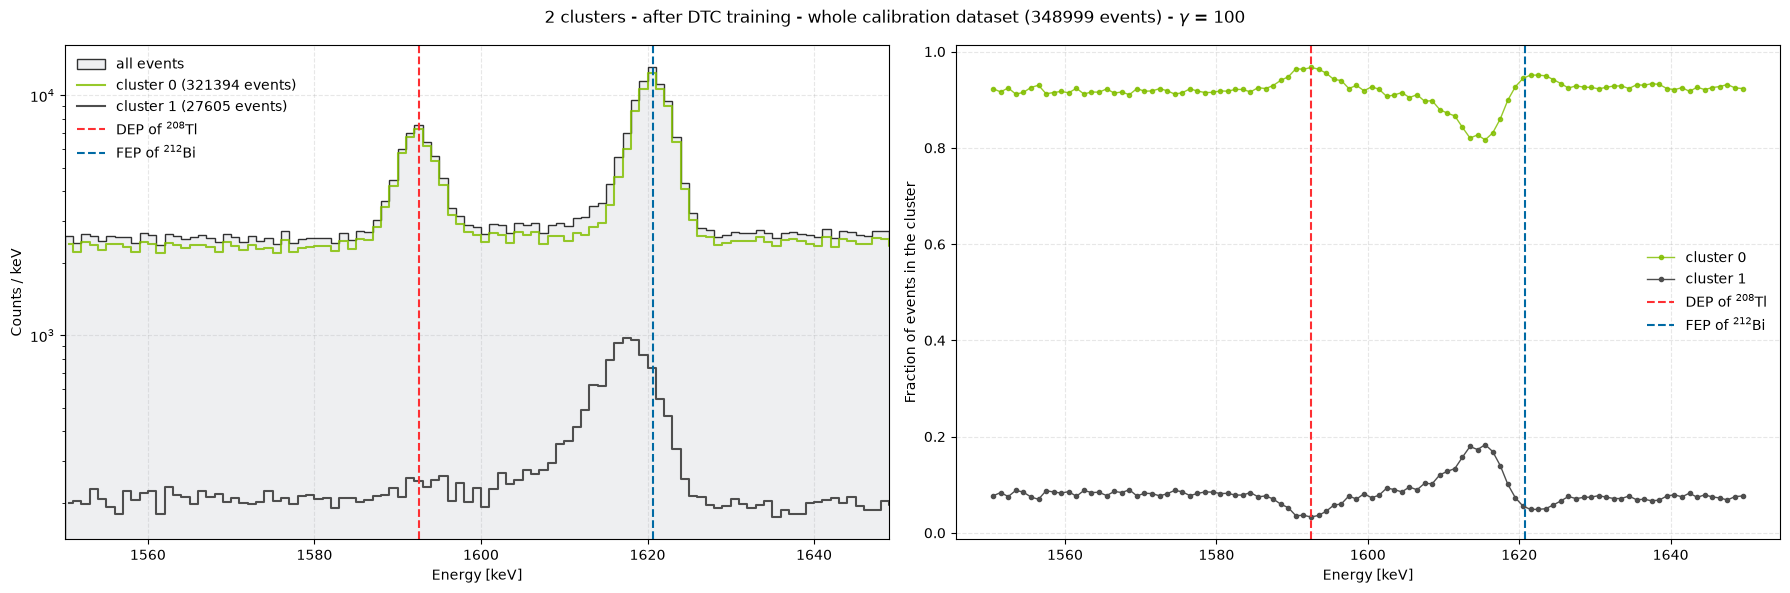

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.888 0.112]
[train] epoch 1/20 - train: -778.8632  val: -742.0222  events per cluster: [0.717 0.283]  changes: 0.1710
        NLL: -800.29   KL: 0.0214
[train] epoch 2/20 - train: -707.1513  val: -697.4207  events per cluster: [0.495 0.505]  changes: 0.2215
        NLL: -772.55   KL: 0.0654
[train] epoch 3/20 - train: -690.8055  val: -692.4010  events per cluster: [0.494 0.506]  changes: 0.0079
        NLL: -766.87   KL: 0.0761
[train] epoch 4/20 - train: -691.0803  val: -693.5402  events per cluster: [0.467 0.533]  changes: 0.0271
        NLL: -768.19   KL: 0.0771
[train] epoch 5/20 - train: -694.6150  val: -693.6771  events per cluster: [0.497 0.503]  changes: 0.0299
        NLL: -771.54   KL: 0.0769
[train] epoch 6/20 - train: -697.6710  val: -680.7524  events per cluster: [0.515 0.485]  changes: 0.0184
     

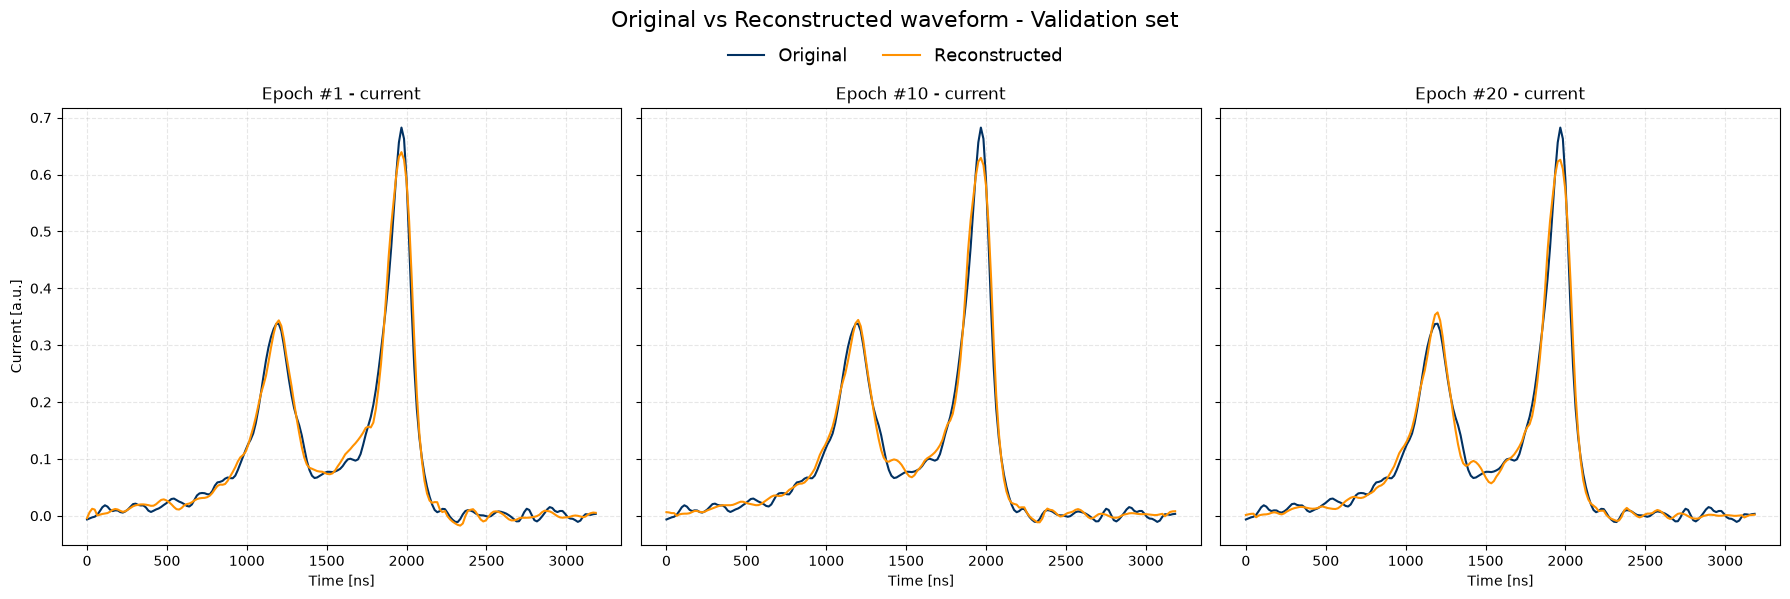

[euclidean, gamma=1000, 2 clusters] events that changed cluster with the training: 0.3896


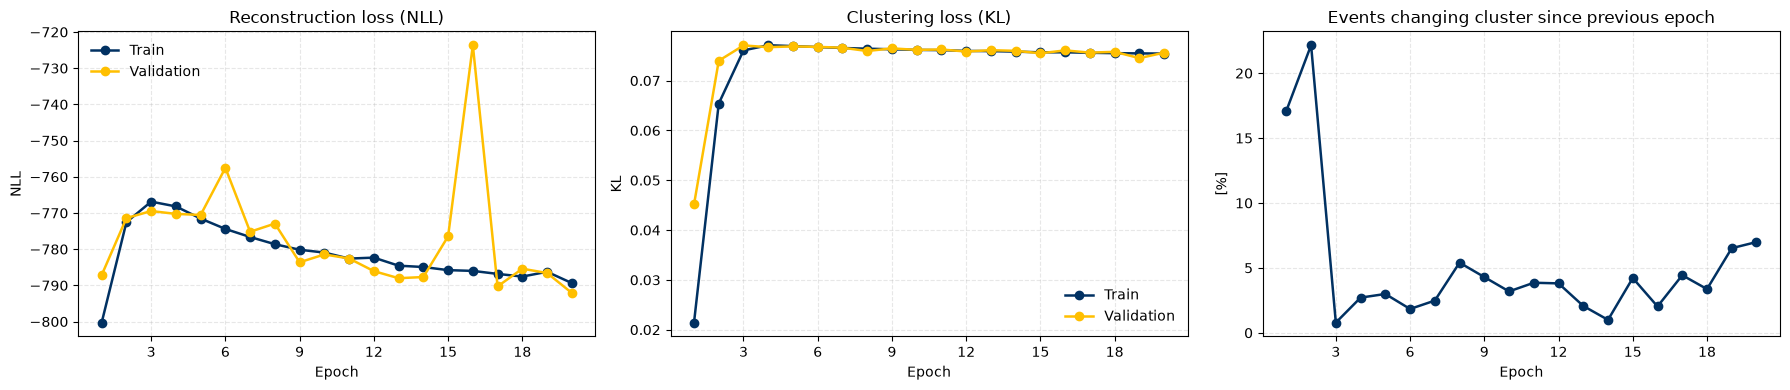

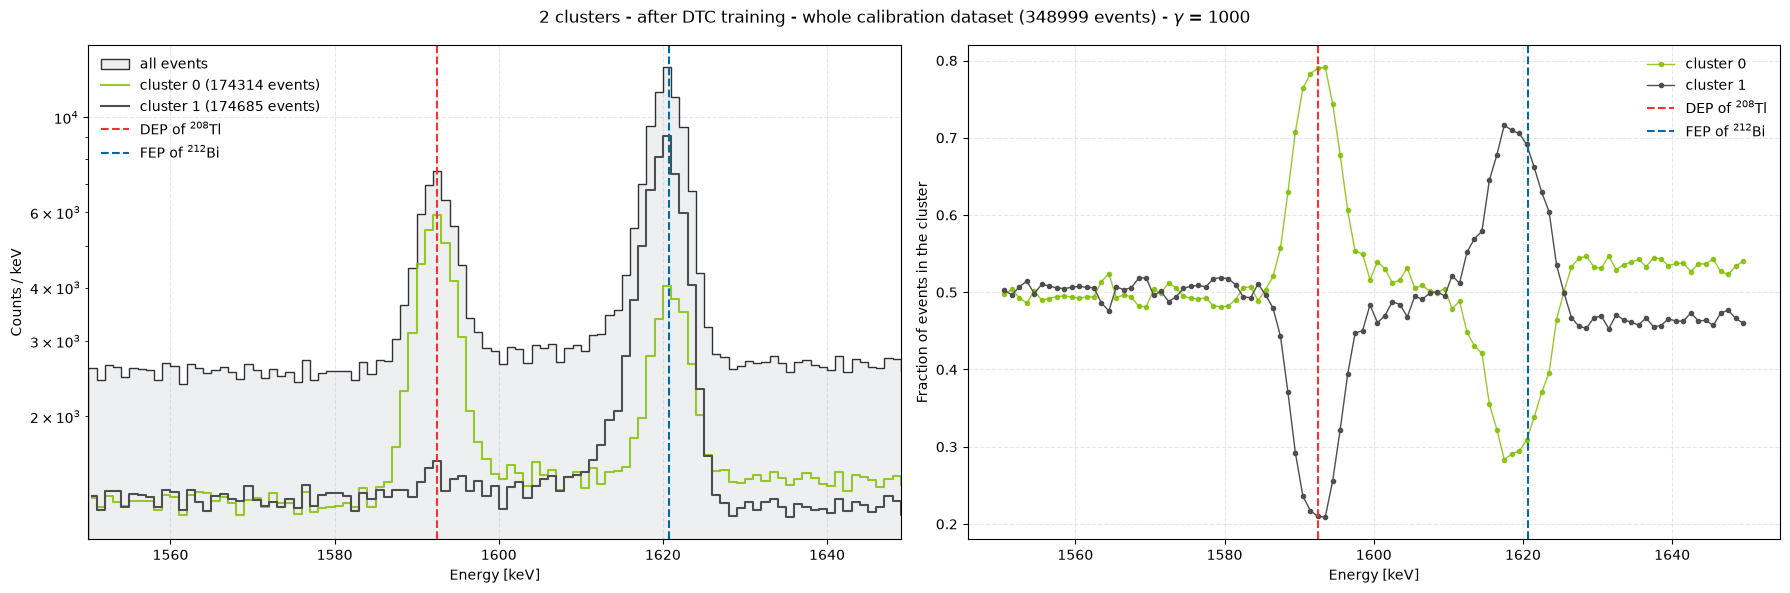

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.113 0.887]
[train] epoch 1/20 - train: 67.4705  val: 92.5548  events per cluster: [0.503 0.497]  changes: 0.3908
        NLL: -599.60   KL: 0.0667
[train] epoch 2/20 - train: 60.2473  val: 42.2800  events per cluster: [0.432 0.568]  changes: 0.0707
        NLL: -641.09   KL: 0.0701
[train] epoch 3/20 - train: 29.8753  val: 28.5398  events per cluster: [0.496 0.504]  changes: 0.0641
        NLL: -658.47   KL: 0.0688
[train] epoch 4/20 - train: 12.6254  val: 25.1619  events per cluster: [0.504 0.496]  changes: 0.0366
        NLL: -673.66   KL: 0.0686
[train] epoch 5/20 - train: 0.4070  val: -16.9878  events per cluster: [0.41 0.59]  changes: 0.0953
        NLL: -676.14   KL: 0.0677
[train] epoch 6/20 - train: -9.4036  val: 53.2022  events per cluster: [0.439 0.561]  changes: 0.0299
        NLL: -681.28   KL: 0.06

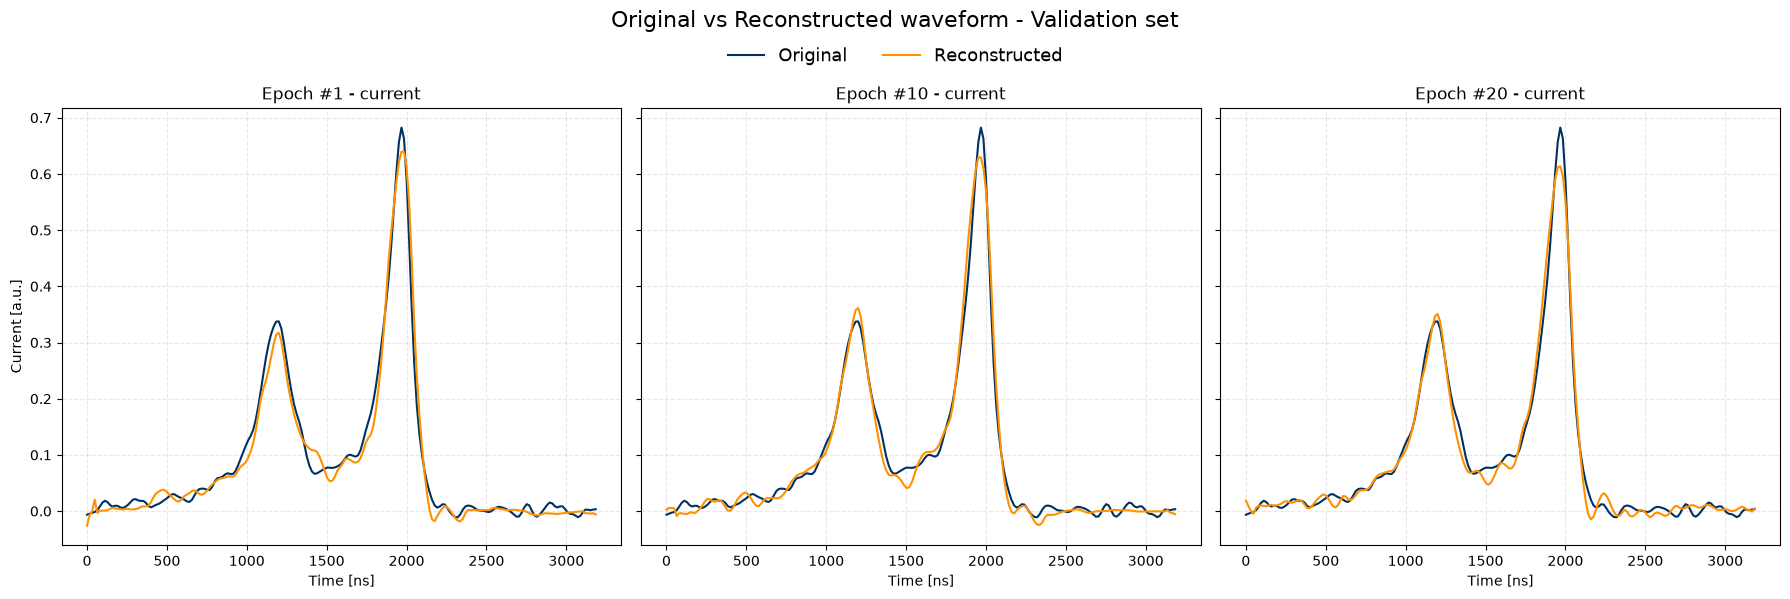

[euclidean, gamma=10000, 2 clusters] events that changed cluster with the training: 0.3827


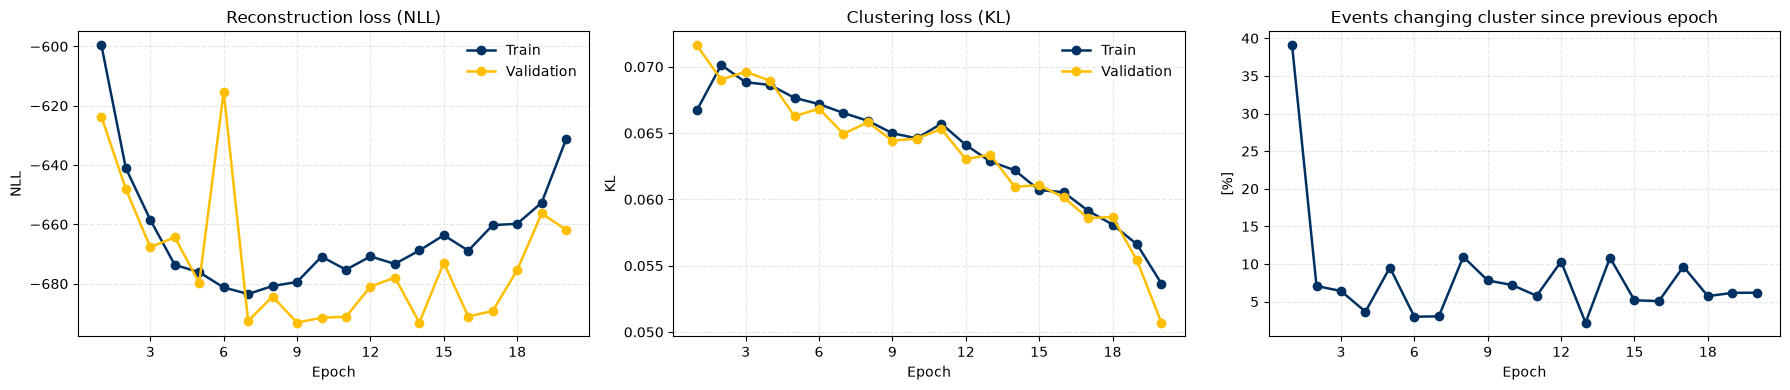

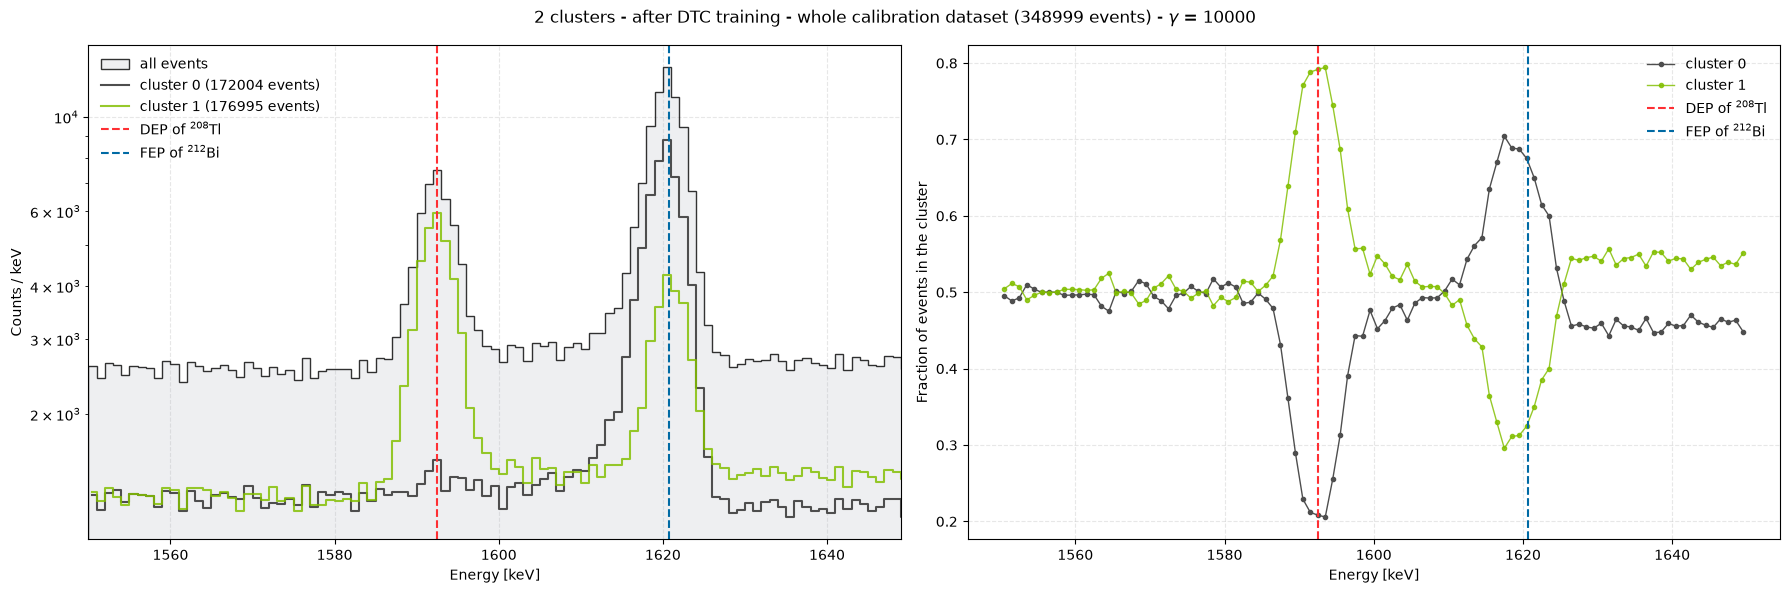

In [70]:
pf.TAG = SCAN_METRIC
scan_gamma = {}
for g in SCAN_GAMMAS:
    pf.PREFIX = f"scan_{SCAN_METRIC}_gamma{g}_"           # also the reconstruction plot made inside DTC.training
    scan_gamma[g] = cluster_run(N_CLUSTERS, METRICS[SCAN_METRIC], gamma=g, epochs=SCAN_EPOCHS)
    plot_energy_and_history(scan_gamma[g], pf.PREFIX, label=f"$\\gamma$ = {g}")

In [71]:
rows = []
for g, r in scan_gamma.items():
    h, y = r['model'].history, r['y']
    s = sse_like(y, N_CLUSTERS)
    keep = y == s
    rows.append({'gamma': g,
                 'NLL validation': h['nll_val'][-1],
                 'NLL change vs pretrain': h['nll_val'][-1] - pre_val_l[-1],
                 'KL validation': h['kl_val'][-1],
                 'gamma x KL': g * h['kl_val'][-1],
                 'moved from KMeans [%]': 100 * (r['y_init'] != y).mean(),
                 'changes last epoch [%]': 100 * h['changes'][-1],
                 'SSE-like kept [%]': 100 * keep.mean(),
                 'DEP kept [%]': 100 * keep[in_dep].mean(),
                 'FEP kept [%]': 100 * keep[in_fep].mean()})
save_table(pd.DataFrame(rows).set_index('gamma'), f'table_scan_{SCAN_METRIC}_gamma')

,NLL validation,NLL change vs pretrain,KL validation,gamma x KL,moved from KMeans [%],changes last epoch [%],SSE-like kept [%],DEP kept [%],FEP kept [%]
gamma,,,,,,,,,
10,-818.08,-18.76,0.01,0.13,4.17,0.11,93.03,95.63,92.31
100,-817.79,-18.47,0.02,1.66,3.23,0.22,92.09,95.09,91.24
1000,-792.09,7.23,0.08,75.61,38.96,6.99,49.95,70.27,35.12
10000,-661.80,137.52,0.05,507.09,38.27,6.19,50.72,70.75,36.39


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_scan_eucl_gamma.csv | table_scan_eucl_gamma.tex


# 2b. SCAN OF THE NUMBER OF CLUSTERS (Euclidean, 30 epochs, $\gamma$ = 1000)
Files `scan_eucl_<K>cl_...`. The run with `N_CLUSTERS` clusters and `GAMMA` is taken from the $\gamma$ scan, not trained again.
Tables: losses per number of clusters, and composition of every cluster (size, fraction of the DEP and of the FEP events).

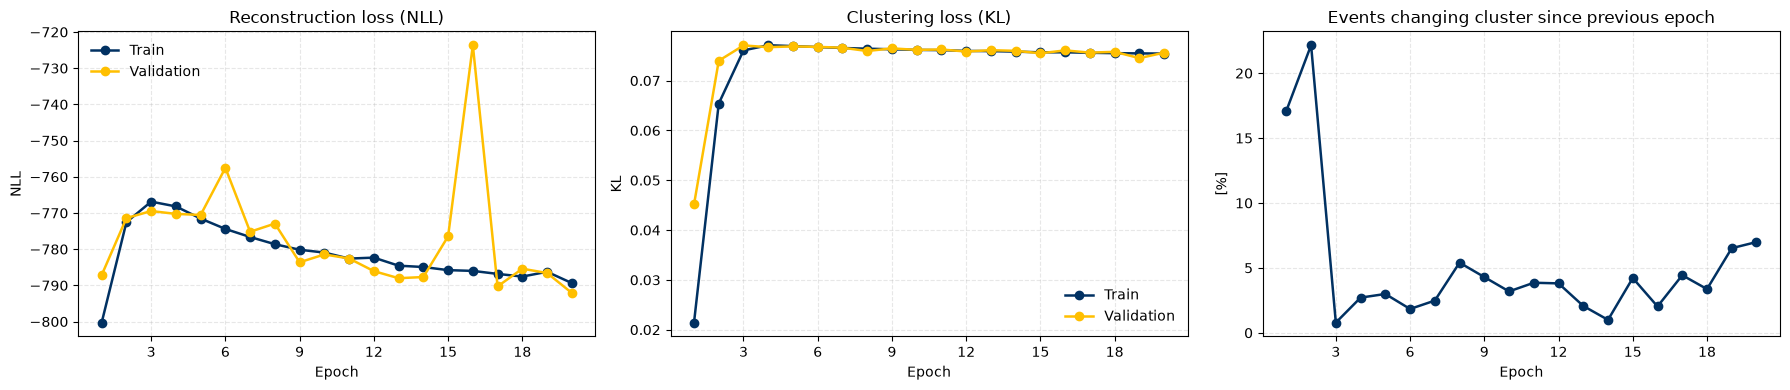

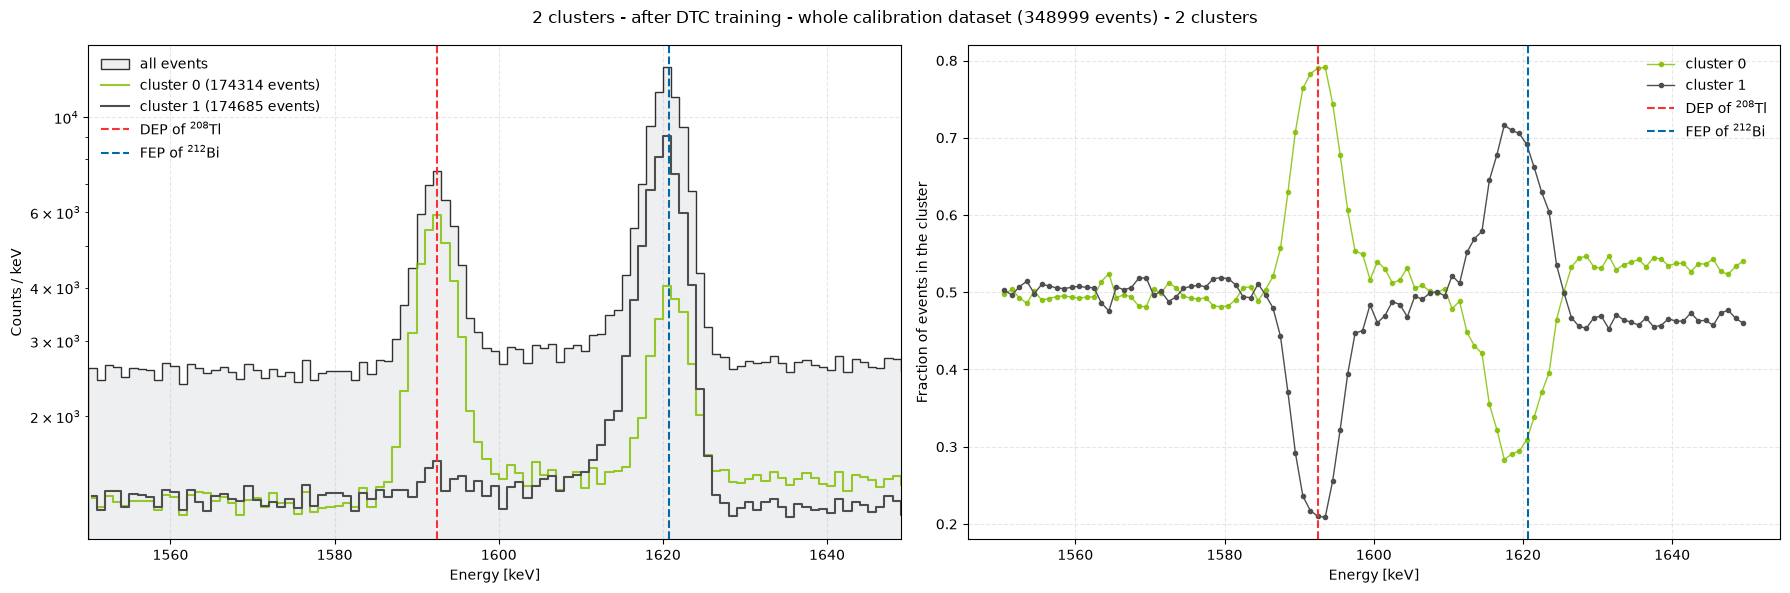

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.8   0.142 0.058]
[train] epoch 1/20 - train: -778.2857  val: -744.5429  events per cluster: [0.    0.632 0.368]  changes: 0.9419
        NLL: -800.58   KL: 0.0223
[train] epoch 2/20 - train: -708.9969  val: -697.8445  events per cluster: [0.    0.501 0.499]  changes: 0.1306
        NLL: -773.52   KL: 0.0645
[train] epoch 3/20 - train: -692.2142  val: -690.8365  events per cluster: [0.    0.512 0.488]  changes: 0.0125
        NLL: -767.98   KL: 0.0758
[train] epoch 4/20 - train: -691.6065  val: -688.4662  events per cluster: [0.    0.509 0.491]  changes: 0.0072
        NLL: -768.82   KL: 0.0772
[train] epoch 5/20 - train: -694.3758  val: -698.8489  events per cluster: [0.    0.473 0.527]  changes: 0.0367
        NLL: -771.36   KL: 0.0770
[train] epoch 6/20 - train: -697.6108  val: -701.7176  events per cluster: 

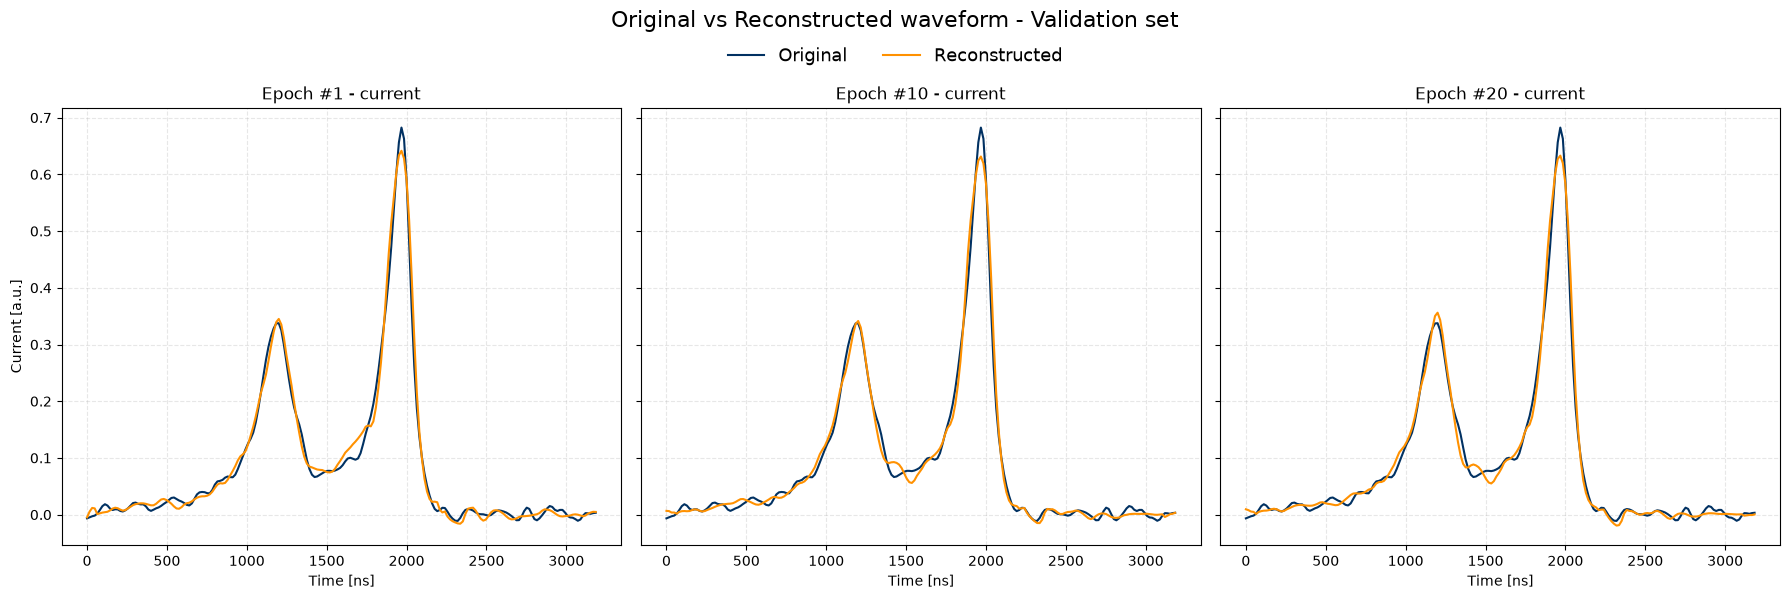

[euclidean, gamma=1000, 3 clusters] events that changed cluster with the training: 0.9411


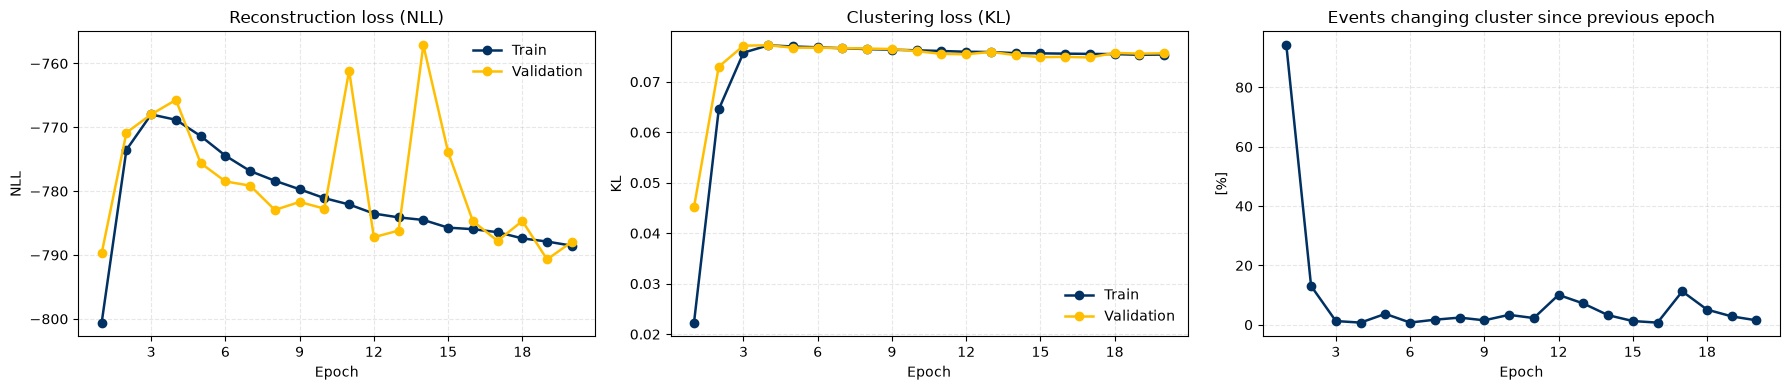

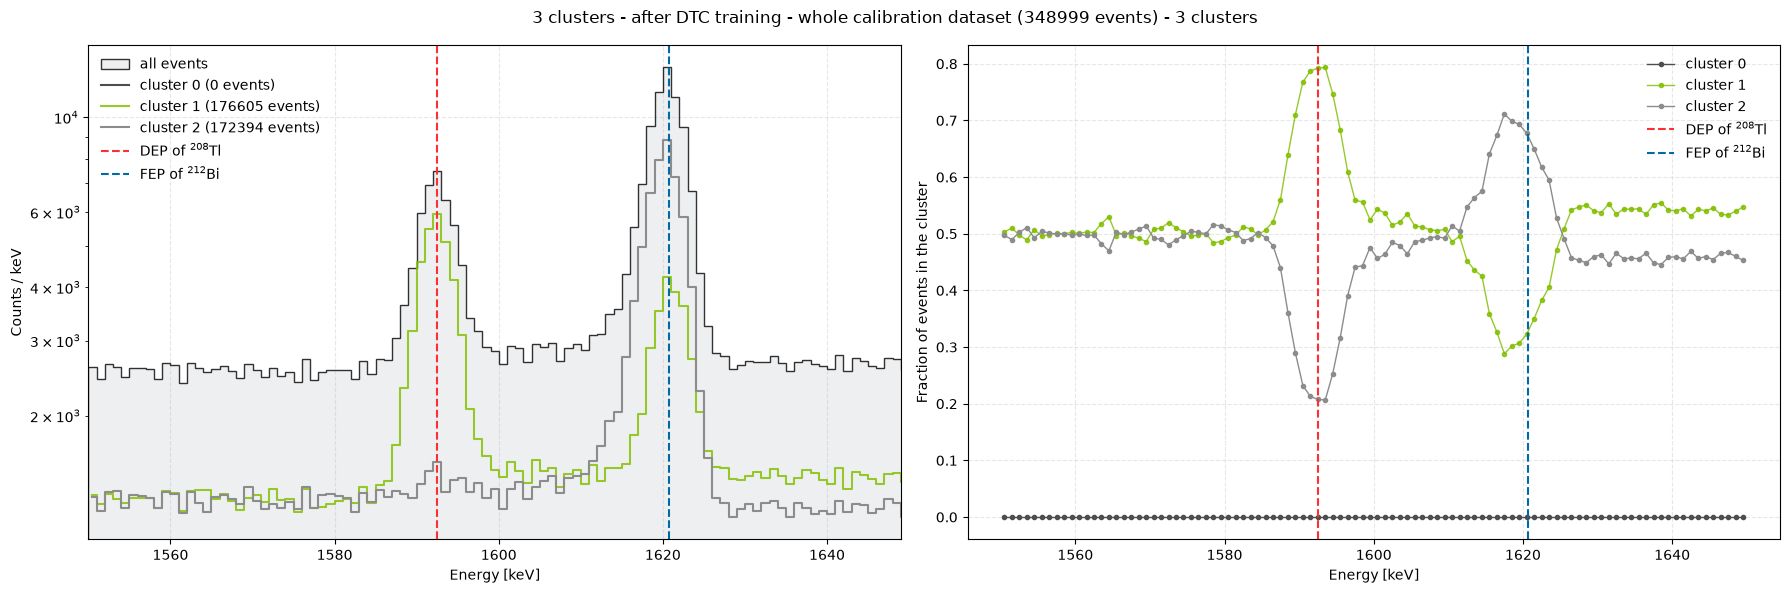

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.085 0.637 0.235 0.043]
[train] epoch 1/20 - train: -779.0257  val: -743.6970  events per cluster: [0.031 0.721 0.    0.249]  changes: 0.3605
        NLL: -800.39   KL: 0.0214
[train] epoch 2/20 - train: -707.3551  val: -697.5111  events per cluster: [0.003 0.491 0.004 0.503]  changes: 0.2579
        NLL: -772.60   KL: 0.0652
[train] epoch 3/20 - train: -690.7731  val: -690.3148  events per cluster: [0.501 0.491 0.    0.008]  changes: 0.5049
        NLL: -766.78   KL: 0.0760
[train] epoch 4/20 - train: -690.9431  val: -690.4182  events per cluster: [0.093 0.    0.5   0.407]  changes: 0.9069
        NLL: -768.04   KL: 0.0771
[train] epoch 5/20 - train: -694.4173  val: -697.1161  events per cluster: [0.509 0.483 0.    0.008]  changes: 0.9084
        NLL: -771.32   KL: 0.0769
[train] epoch 6/20 - train: -697.3573  

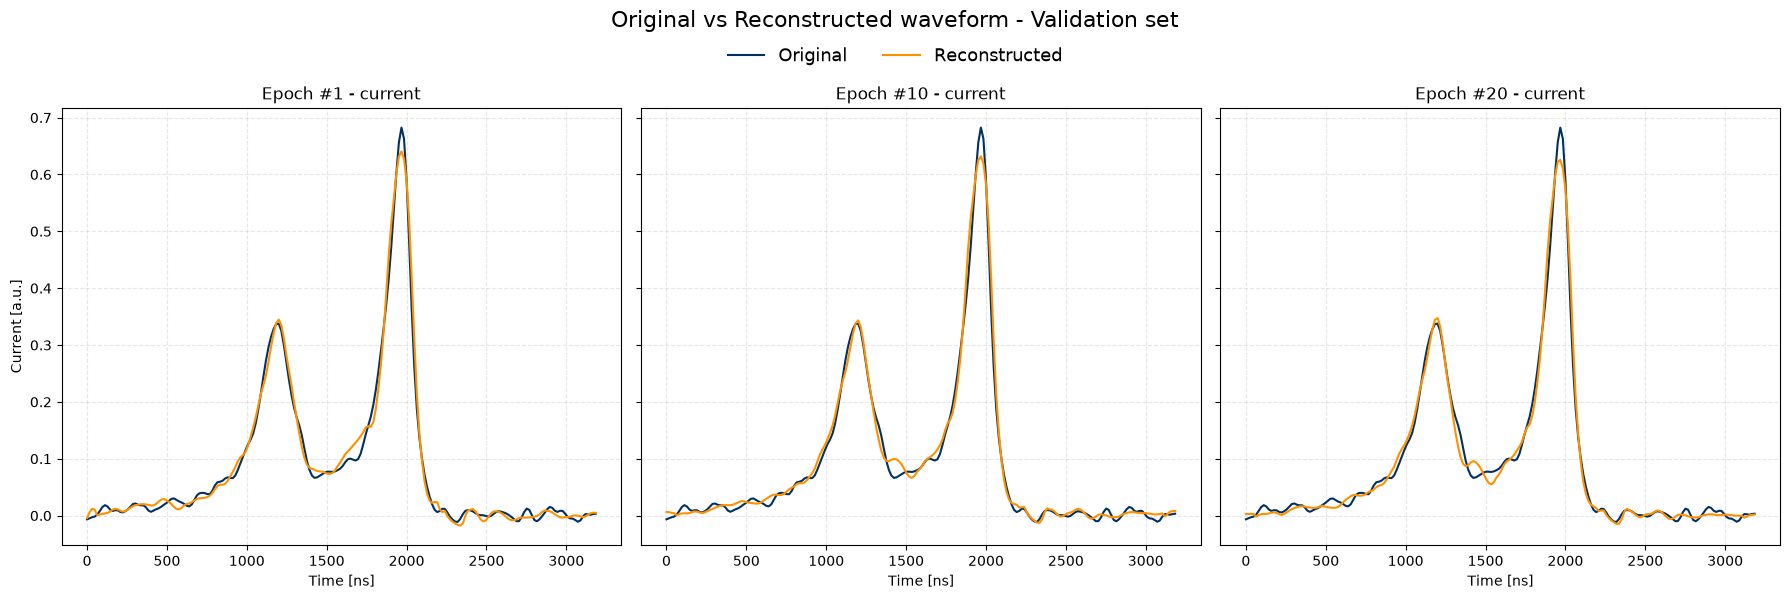

[euclidean, gamma=1000, 4 clusters] events that changed cluster with the training: 0.4419


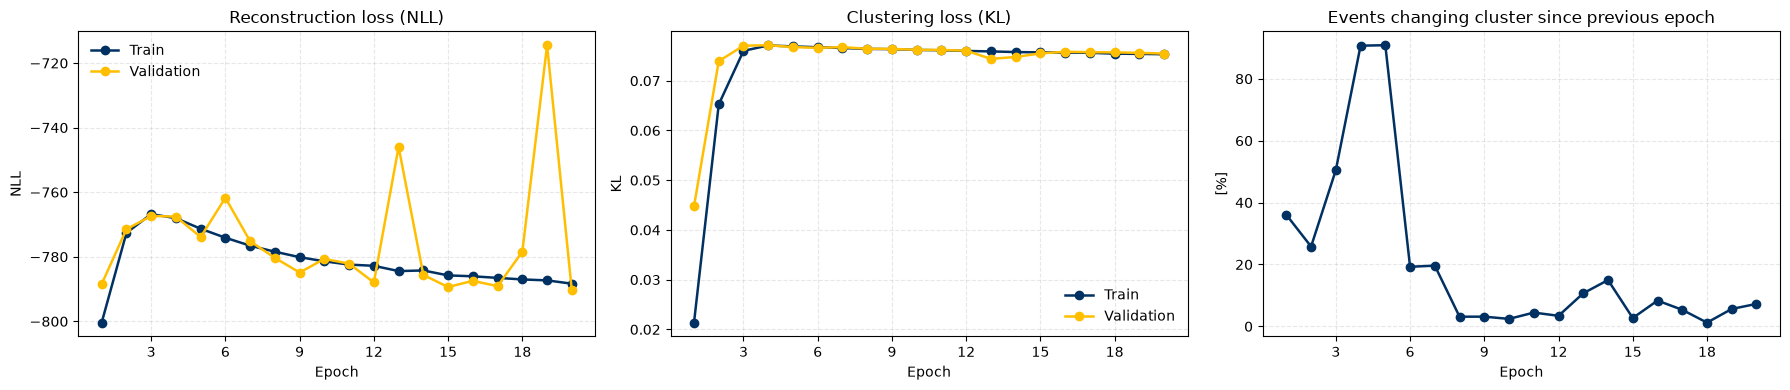

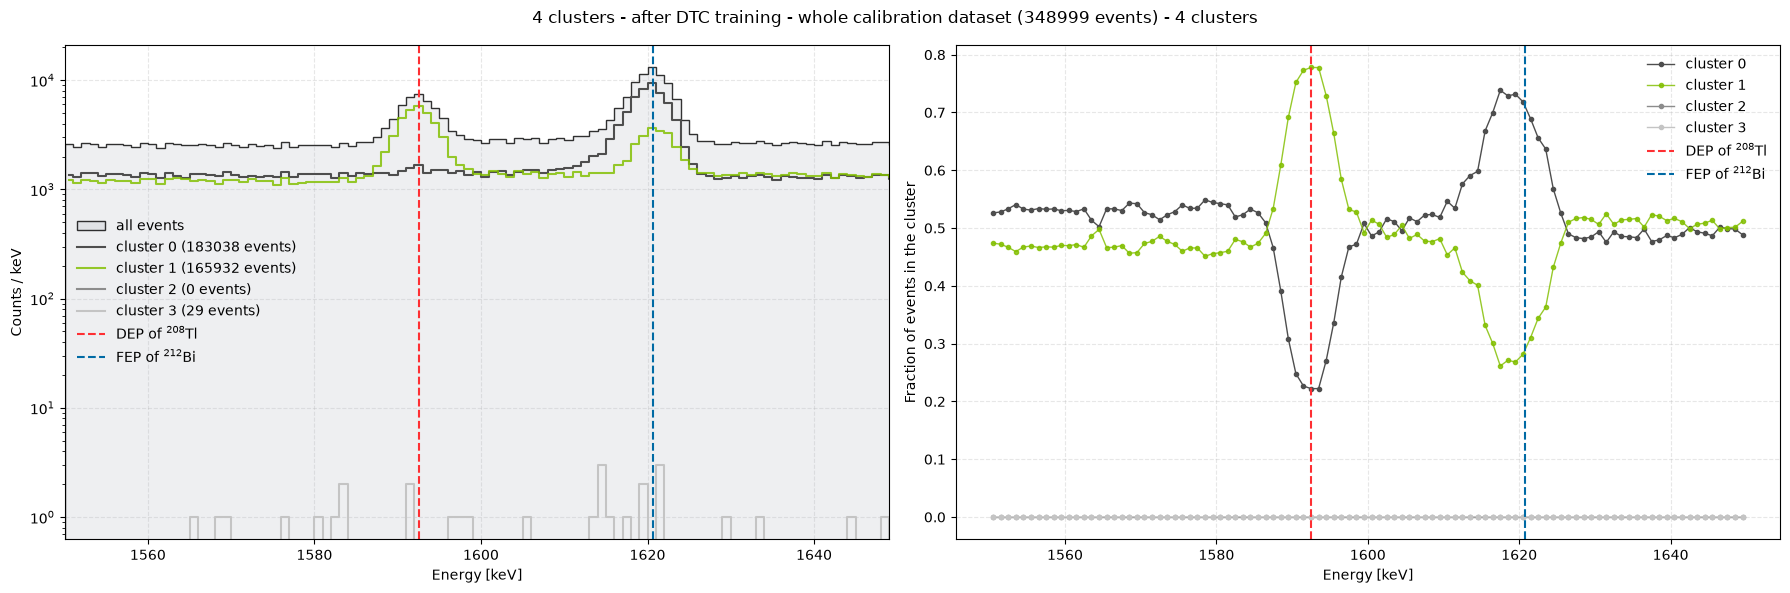

In [72]:
pf.TAG = SCAN_METRIC
scan_k = {}
for k in SCAN_CLUSTERS:
    if k == N_CLUSTERS and GAMMA in scan_gamma:
        scan_k[k] = scan_gamma[GAMMA]                       # same run: no need to train it again
    else:
        pf.PREFIX = f"scan_{SCAN_METRIC}_"                   # files scan_eucl_<K>cl_...
        scan_k[k] = cluster_run(k, METRICS[SCAN_METRIC], gamma=GAMMA, epochs=SCAN_EPOCHS)
    plot_energy_and_history(scan_k[k], f"scan_{SCAN_METRIC}_", label=f"{k} clusters")

In [73]:
loss_rows, comp_rows = [], []
for k, r in scan_k.items():
    h, y = r['model'].history, r['y']
    loss_rows.append({'clusters': k,
                      'NLL validation': h['nll_val'][-1],
                      'NLL change vs pretrain': h['nll_val'][-1] - pre_val_l[-1],
                      'KL validation': h['kl_val'][-1],
                      'moved from KMeans [%]': 100 * (r['y_init'] != y).mean(),
                      'changes last epoch [%]': 100 * h['changes'][-1]})
    size, dep_f, fep_f = composition(y, k)
    for j in range(k):
        comp_rows.append({'clusters / cluster': f"{k} / {j}", 'events [%]': 100 * size[j],
                          'DEP events in the cluster [%]': 100 * dep_f[j],
                          'FEP events in the cluster [%]': 100 * fep_f[j]})
save_table(pd.DataFrame(loss_rows).set_index('clusters'), f'table_scan_{SCAN_METRIC}_clusters_losses')
save_table(pd.DataFrame(comp_rows).set_index('clusters / cluster'), f'table_scan_{SCAN_METRIC}_clusters_composition')

,NLL validation,NLL change vs pretrain,KL validation,moved from KMeans [%],changes last epoch [%]
clusters,,,,,
2,-792.09,7.23,0.08,38.96,6.99
3,-787.93,11.38,0.08,94.11,1.49
4,-790.44,8.88,0.08,44.19,7.26


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_scan_eucl_clusters_losses.csv | table_scan_eucl_clusters_losses.tex


,events [%],DEP events in the cluster [%],FEP events in the cluster [%]
clusters / cluster,,,
2 / 0,49.95,70.27,35.12
2 / 1,50.05,29.73,64.88
3 / 0,0.00,0.00,0.00
3 / 1,50.60,70.67,36.10
3 / 2,49.40,29.33,63.90
4 / 0,52.45,31.31,67.40
4 / 1,47.55,68.68,32.58
4 / 2,0.00,0.00,0.00
4 / 3,0.01,0.01,0.01


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_scan_eucl_clusters_composition.csv | table_scan_eucl_clusters_composition.tex


events per cluster: {0: 183038, 1: 165932, 2: 0, 3: 29}
cluster 0: 183038 events | mean A/E = -30.340 | median A/E = -27.409
cluster 1: 165932 events | mean A/E = -1.350 | median A/E = -0.438
event 6320: E = 1576.53 keV | A/E = -54.446 | rise time = 2288 ns | max current = 0.686
event 17871: E = 1591.55 keV | A/E = -46.770 | rise time = 912 ns | max current = 0.727
event 44031: E = 1583.01 keV | A/E = -13.308 | rise time = 1056 ns | max current = 0.986
event 59592: E = 1565.93 keV | A/E = -21.888 | rise time = 464 ns | max current = 0.925
event 67167: E = 1619.23 keV | A/E = -7.924 | rise time = 528 ns | max current = 1.018
event 74839: E = 1629.52 keV | A/E = -3.611 | rise time = 544 ns | max current = 1.066
event 96880: E = 1615.62 keV | A/E = -33.231 | rise time = 912 ns | max current = 0.908
event 124661: E = 1614.61 keV | A/E = -70.911 | rise time = 864 ns | max current = 0.561
event 128229: E = 1569.22 keV | A/E = 158.368 | rise time = 160 ns | max current = 2.308
event 145522: E

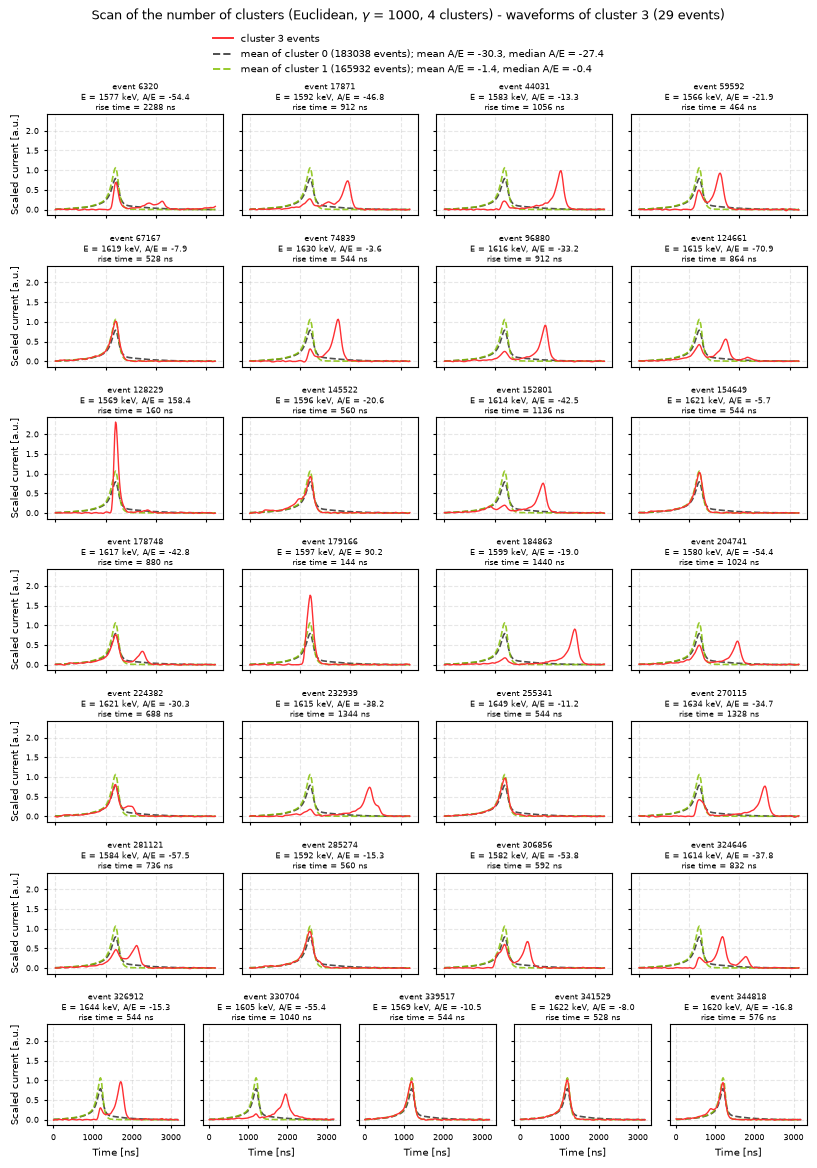

In [83]:
# ---- waveforms of cluster 3 in the scan with 4 clusters: A4 page, one panel per event ----
import math
from matplotlib.lines import Line2D

K, CL = 4, 3
NCOLS, LAST_COLS = 4, 5                                             # 29 events -> 6 rows of 4 + 1 row of 5
PAGE_W, PAGE_H = 8.27, 11.69                                        # A4 in inches
r  = scan_k[K]
yk = r['y']
print("events per cluster:", {j: int((yk == j).sum()) for j in range(K)})

idx = np.flatnonzero(yk == CL)
cur = data['waves'][:, 0, :]
cur = cur.cpu().numpy() if hasattr(cur, 'cpu') else np.asarray(cur)
rt  = np.asarray(clean['rise_time_all'])[data['idx_sel']]          # same order as data['energy']
aoe = np.asarray(clean['AoE_all'])[data['idx_sel']]                # same mapping
t   = np.arange(cur.shape[1]) * 16                                  # ns

EVENT_COLOR = '#fe2f33'                                             # events of cluster 3
MEAN_COLORS = {0: '#4e4e4e', 1: '#82bf00d4', 2: '#013162', 3: '#013162'}   # means of the other clusters

# mean waveforms of the non-empty clusters (drawn in every panel)
means = []
for j in range(K):
    m = yk == j
    if j != CL and m.sum() > 100:
        means.append((j, cur[m].mean(axis=0),
                      f"mean of cluster {j} ({m.sum()} events); "
                      f"mean A/E = {np.nanmean(aoe[m]):.1f}, median A/E = {np.nanmedian(aoe[m]):.1f}"))
        print(f"cluster {j}: {m.sum()} events | mean A/E = {np.nanmean(aoe[m]):.3f} | median A/E = {np.nanmedian(aoe[m]):.3f}")

n_ev = len(idx)

# rows of NCOLS panels, last row of LAST_COLS panels
row_sizes, left = [], n_ev
while left > LAST_COLS:
    take = min(NCOLS, left)
    row_sizes.append(take)
    left -= take
if left > 0:
    row_sizes.append(left)
nrows = max(len(row_sizes), 1)

GRID = 20                                                           # virtual columns: 4 panels x 5 = 5 panels x 4
fig = plt.figure(figsize=(PAGE_W, PAGE_H))
gs = fig.add_gridspec(nrows, GRID)

axes, first_ax = [], None
for r_i, k in enumerate(row_sizes):
    span = GRID // k                                                # width of each panel in this row
    for c_i in range(k):
        ax = fig.add_subplot(gs[r_i, c_i * span:(c_i + 1) * span], sharey=first_ax)
        if first_ax is None:
            first_ax = ax
        axes.append((ax, r_i, c_i))

for n, (ax, r_i, c_i) in enumerate(axes):
    i = idx[n]
    for j, mean_wf, lab in means:
        ax.plot(t, mean_wf, ls='--', lw=1.2, color=MEAN_COLORS[j])
    ax.plot(t, cur[i], lw=1.0, color=EVENT_COLOR)
    print(f"event {i}: E = {energy[i]:.2f} keV | A/E = {aoe[i]:.3f} | rise time = {rt[i]:.0f} ns | max current = {cur[i].max():.3f}")

    ax.set_title(f"event {i}\nE = {energy[i]:.0f} keV, A/E = {aoe[i]:.1f}\nrise time = {rt[i]:.0f} ns",
                 fontsize=6, pad=3)
    ax.tick_params(labelsize=6, length=2.5)
    ax.grid(alpha=0.3, ls='--'); ax.set_axisbelow(True)
    if c_i == 0:                                                    # y label only on the first column
        ax.set_ylabel("Scaled current [a.u.]", fontsize=7)
    else:
        ax.tick_params(labelleft=False)
    if r_i == nrows - 1:                                            # x label only on the last row
        ax.set_xlabel("Time [ns]", fontsize=7)
    else:
        ax.tick_params(labelbottom=False)

# one common legend for the whole figure
handles = [Line2D([0], [0], color=EVENT_COLOR, lw=1.4, label=f"cluster {CL} events")]
handles += [Line2D([0], [0], color=MEAN_COLORS[j], lw=1.4, ls='--', label=lab) for j, _, lab in means]

if n_ev:
    print(f"cluster {CL}: {n_ev} events | mean A/E = {np.nanmean(aoe[idx]):.3f}")

fig.suptitle(f"Scan of the number of clusters ({NAMES[SCAN_METRIC]}, $\\gamma$ = {GAMMA}, {K} clusters) - "
             f"waveforms of cluster {CL} ({n_ev} events)", fontsize=9, y=0.995)
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.982),
           ncol=1, frameon=False, fontsize=7)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(os.path.join(pf.PLOT_DIR, f"scan_{SCAN_METRIC}_{K}cl_cluster{CL}_waveforms.pdf"), dpi=300)   # no bbox_inches='tight': keeps the exact A4 size
plt.show()

# 3. FINAL RUNS: ACF, EUCLIDEAN, CID
2 clusters, $\gamma$ = 1000, `TRAINING_EPOCHS` epochs. For every metric (files `<metric>_...`):
- reconstruction after the training (made inside `DTC.training`) and training history;
- table of the losses of every epoch;
- clusters vs energy and A/E + rise time on the **training**, **validation** and **test** set;
- weights and bundle saved in `finalmodels/` (format read by DTC-allMETRICS and by the 2$\nu\beta\beta$ analysis).

In [75]:
def run_final(tag):
    
    metric = METRICS[tag]
    pf.TAG, pf.PREFIX = tag, f"{tag}_"
    run = cluster_run(N_CLUSTERS, metric, gamma=GAMMA, epochs=TRAINING_EPOCHS)
    y = run['y']
    colors = pf.cluster_colors(y, energy, N_CLUSTERS)       # from ALL the events: same colors in every plot
    
    pf.plot_training_history(run['model'].history, name=f"{N_CLUSTERS}cl_training_history")
    for split in ('train', 'val', 'test'):
        idx = data[f'idx_{split}']
        title = pf._title(N_CLUSTERS, split, len(idx))
        pf.plot_clusters_vs_energy(y[idx], energy[idx], N_CLUSTERS, title=title,
                                   name=f"{N_CLUSTERS}cl_energy_{split}", colors=colors)
        pf.plot_cluster_variables(y[idx], data['AoE'][idx], data['rise_time'][idx], N_CLUSTERS, title=title,
                                  name=f"{N_CLUSTERS}cl_AoE_risetime_{split}", colors=colors)
    
    save_table(training_table(run), f'table_{tag}_training_losses')
    
    # SSE-like cluster and saving (same formats as before)
    run['sse_cluster'] = s = sse_like(y, N_CLUSTERS)
    _, dep_f, fep_f = composition(y, N_CLUSTERS)
    print(f"{metric}: DEP per cluster {np.round(dep_f, 3)} | FEP per cluster {np.round(fep_f, 3)} -> SSE-like cluster = {s}")
    
    base = os.path.join(OUT_DIR, f"dtc{N_CLUSTERS}_{metric}_gamma{GAMMA}_{TRAINING_EPOCHS}ep")
    model = run['model']
    torch.save({'state_dict': model.state_dict(), 'sse_cluster': s}, base + ".pth")
    bundle = dict(
        state_dict=model.state_dict(),
        model_kwargs=dict(input_length=int(data['waves'].shape[-1]), pool_size=10, n_clusters=N_CLUSTERS,
                          distance_metric=metric, use_charge=use_charge),
        config={k: (v.item() if hasattr(v, 'item') else v) for k, v in data['config'].items()},
        scale_factor=float(data['scale_factor']),
        charge_scale_factor=float(data['charge_scale_factor']),
        channels=int(data['channels']),
        wfcleaning_file=os.path.abspath(preliminary.wfcleaning.__file__),
        cleaning_kwargs=dict(baseline_points=300, n_sigmas=3, pre_trigger_points=75, post_trigger_points=124),
        dep_frac=dep_f, fep_frac=fep_f, sse_cluster=s,
        gamma=GAMMA, epochs=TRAINING_EPOCHS, pretraining_epochs=PRETRAINING_EPOCHS, tae_file=os.path.abspath(TAE_PATH),
    )
    torch.save(bundle, base + "_bundle.pth")
    print("saved:", os.path.abspath(base + ".pth"), "|", os.path.abspath(base + "_bundle.pth"))
    return run


runs = {}

#### ACF

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.917 0.083]
[train] epoch 1/20 - train: -804.1125  val: -805.8895  events per cluster: [0.734 0.266]  changes: 0.1829
        NLL: -807.73   KL: 0.0036
[train] epoch 2/20 - train: -807.0074  val: -807.7183  events per cluster: [0.534 0.466]  changes: 0.2001
        NLL: -811.28   KL: 0.0043
[train] epoch 3/20 - train: -806.2296  val: -804.1610  events per cluster: [0.528 0.472]  changes: 0.0089
        NLL: -811.13   KL: 0.0049
[train] epoch 4/20 - train: -804.5698  val: -804.6717  events per cluster: [0.473 0.527]  changes: 0.0548
        NLL: -810.58   KL: 0.0060
[train] epoch 5/20 - train: -796.5187  val: -777.9433  events per cluster: [0.547 0.453]  changes: 0.0909
        NLL: -807.35   KL: 0.0108
[train] epoch 6/20 - train: -722.0702  val: -693.7258  events per cluster: [0.518 0.482]  changes: 0.0516
     

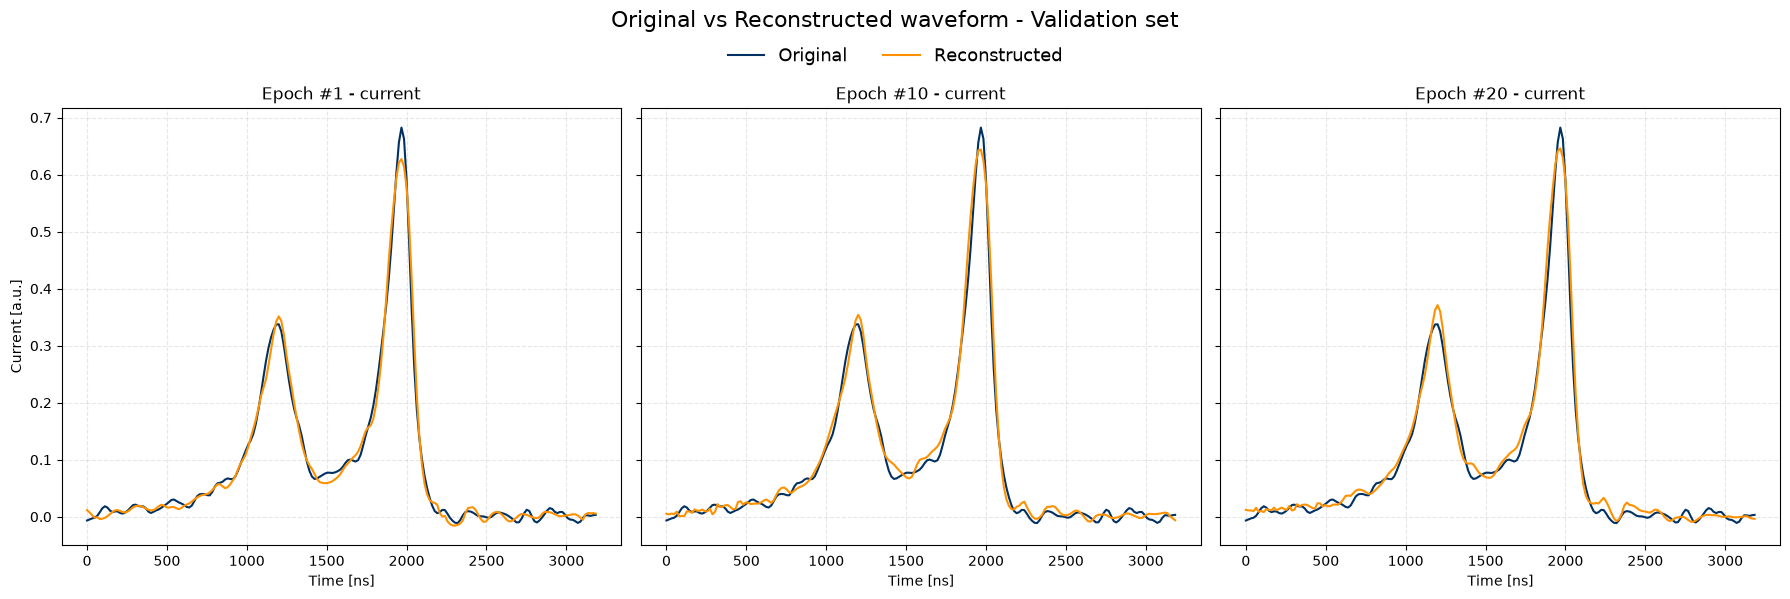

[acf, gamma=1000, 2 clusters] events that changed cluster with the training: 0.4448


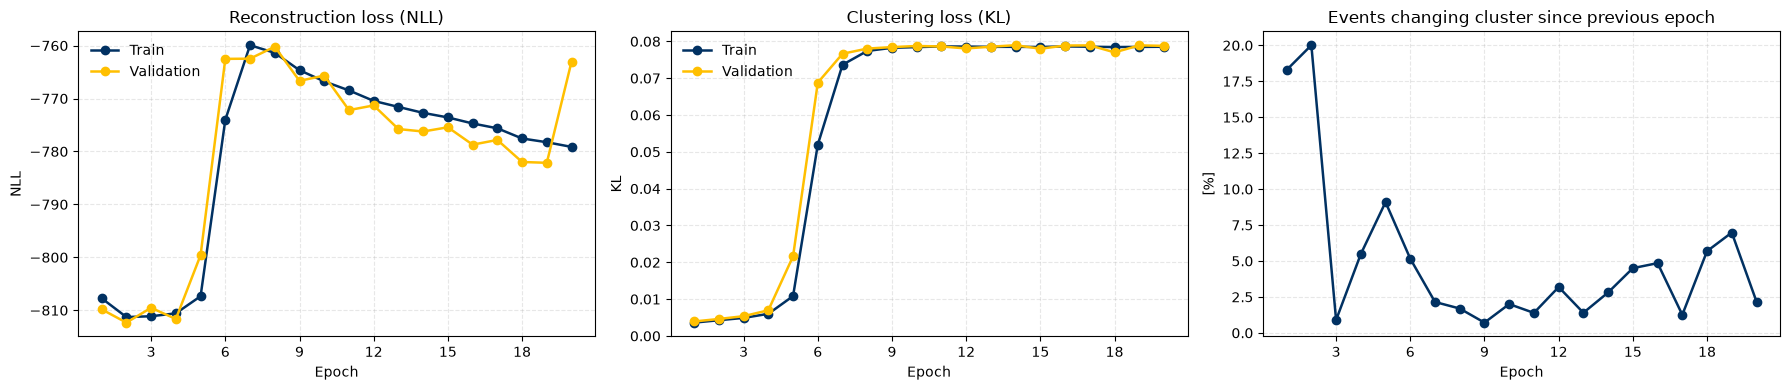

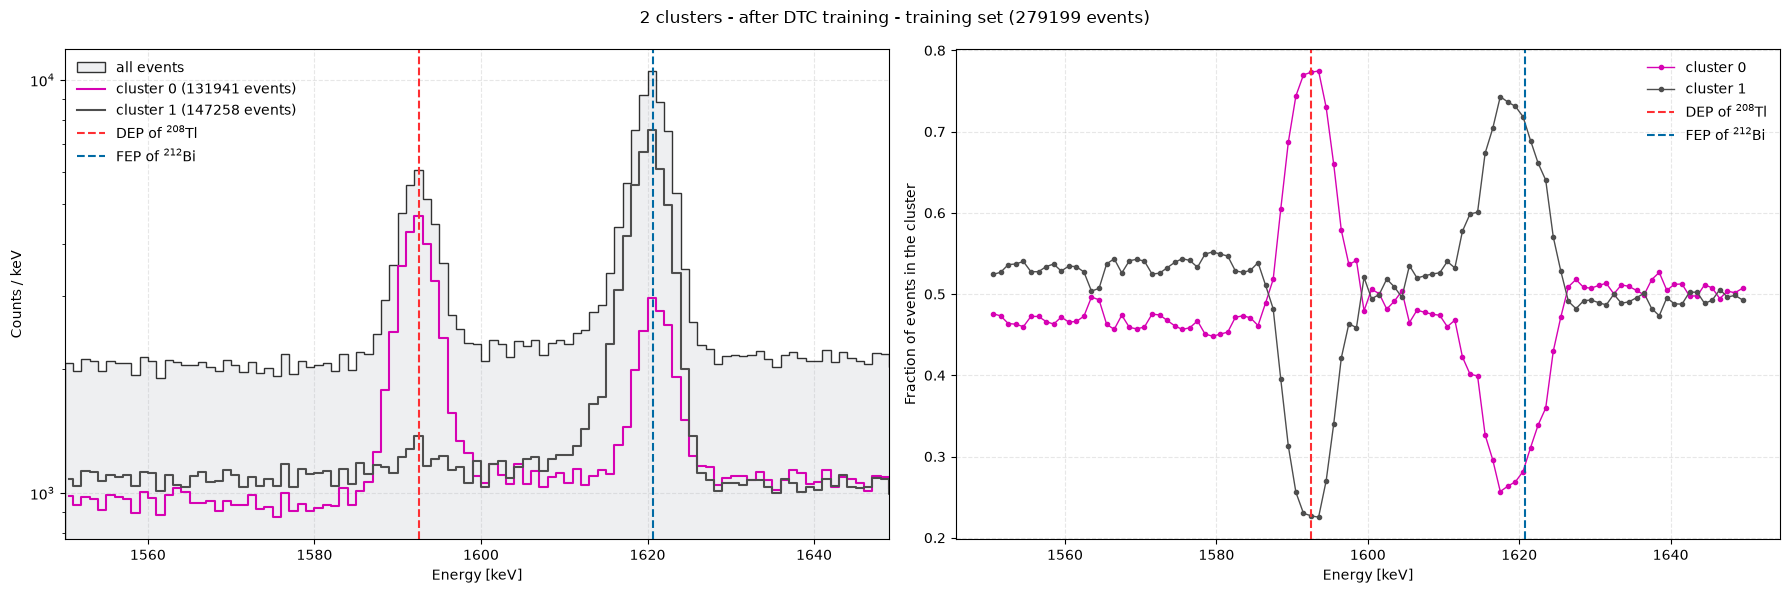

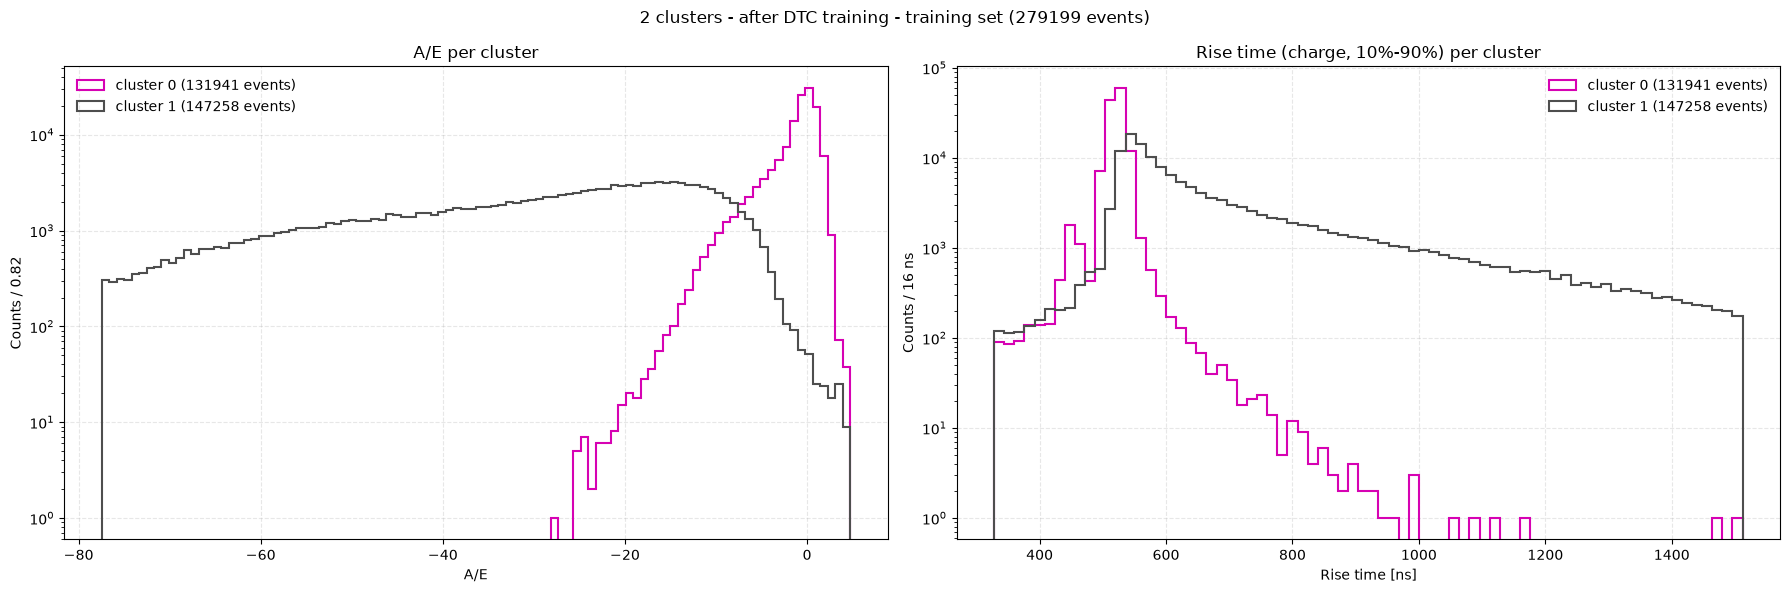

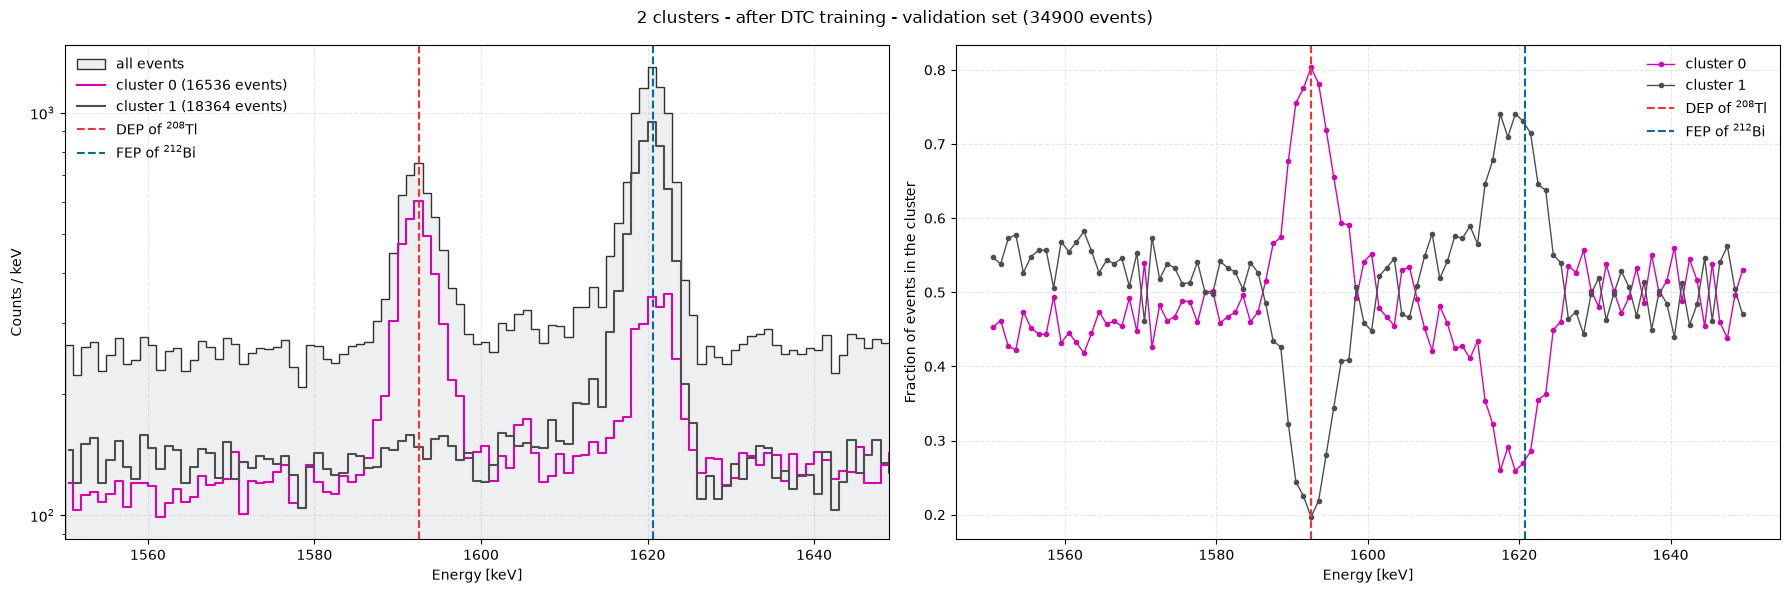

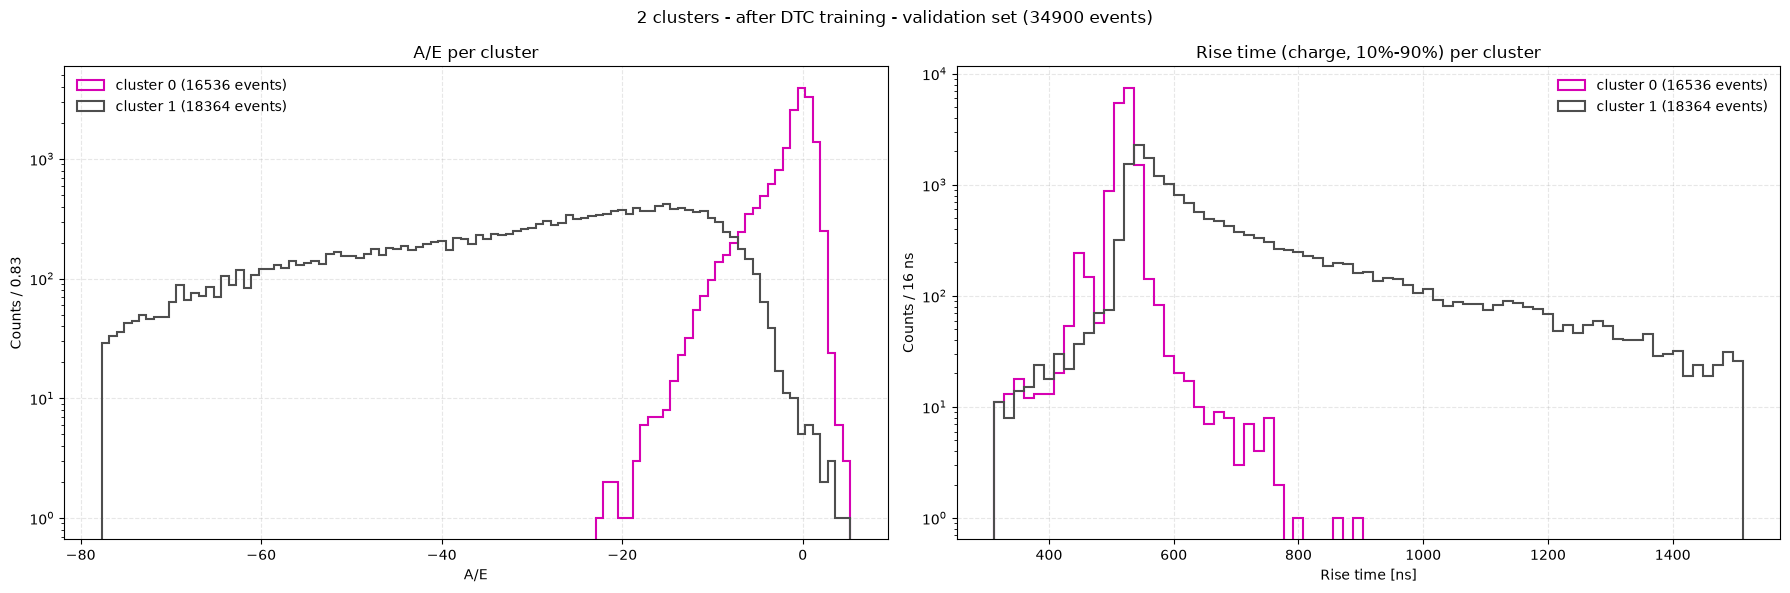

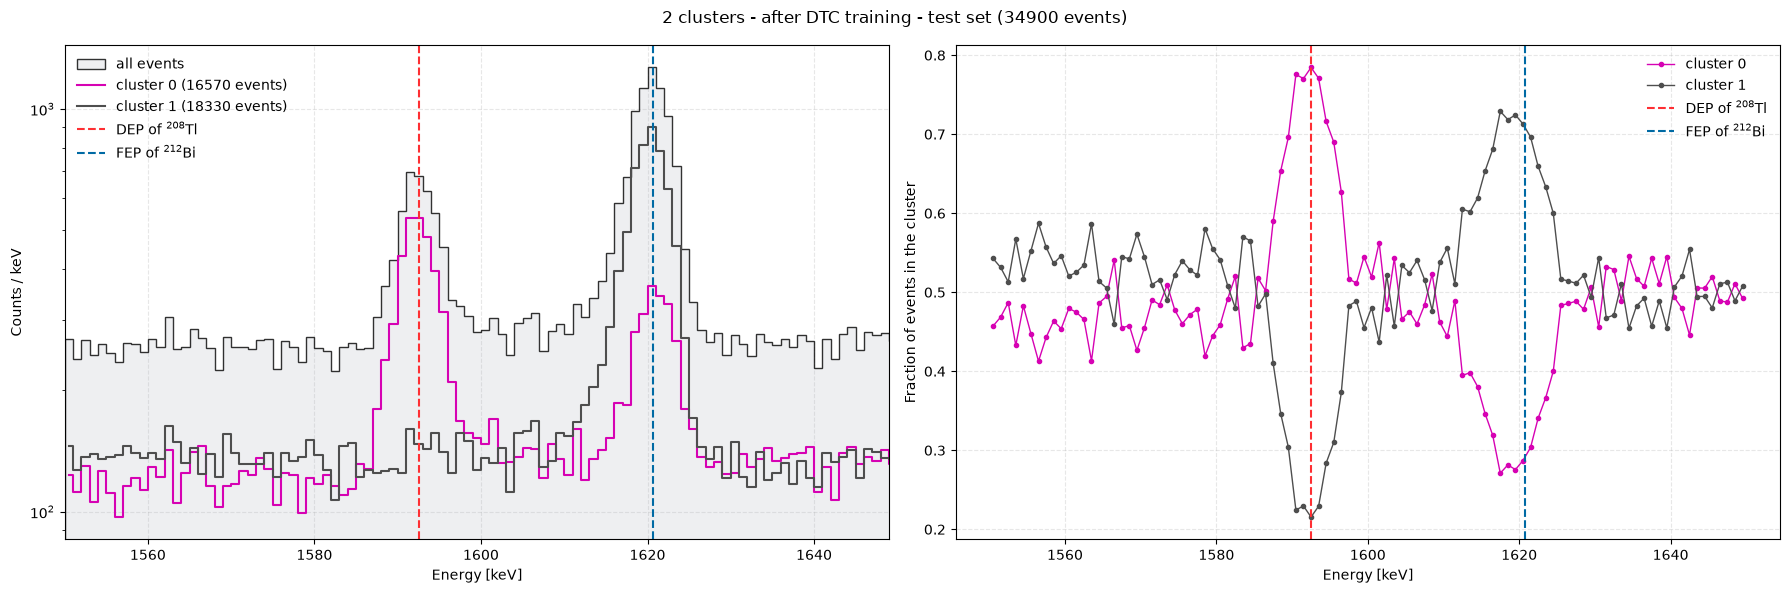

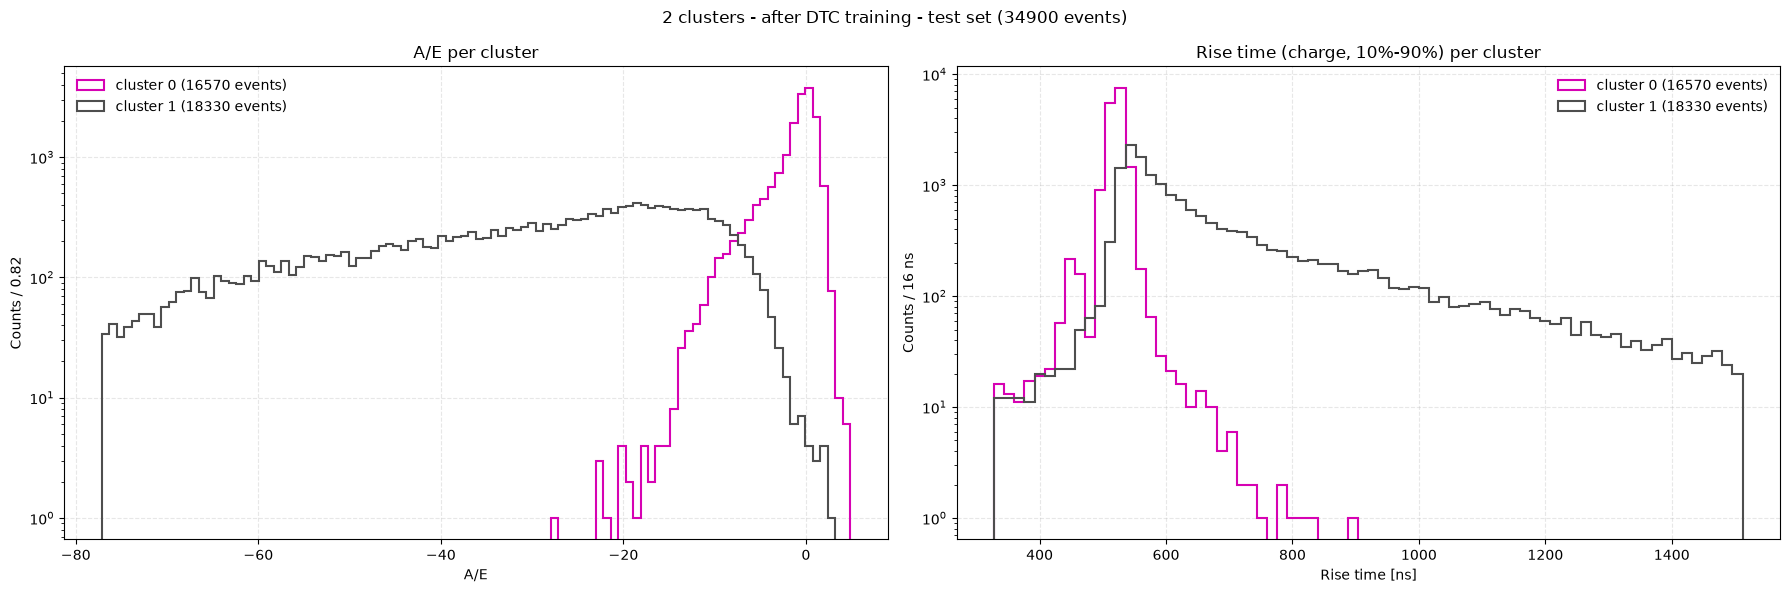

,total train,total validation,NLL train,NLL validation,KL train,KL validation,changes [%],events per cluster
epoch,,,,,,,,
1,-804.11,-805.89,-807.73,-809.82,0.00,0.00,18.29,0.73/0.27
2,-807.01,-807.72,-811.28,-812.33,0.00,0.00,20.01,0.53/0.47
3,-806.23,-804.16,-811.13,-809.53,0.00,0.01,0.89,0.53/0.47
4,-804.57,-804.67,-810.58,-811.65,0.01,0.01,5.48,0.47/0.53
5,-796.52,-777.94,-807.35,-799.58,0.01,0.02,9.09,0.55/0.45
6,-722.07,-693.73,-774.02,-762.51,0.05,0.07,5.16,0.52/0.48
7,-686.29,-685.84,-759.93,-762.48,0.07,0.08,2.15,0.50/0.50
8,-683.98,-682.17,-761.38,-760.20,0.08,0.08,1.69,0.48/0.52
9,-686.40,-688.22,-764.65,-766.66,0.08,0.08,0.71,0.48/0.52


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_acf_training_losses.csv | table_acf_training_losses.tex
acf: DEP per cluster [0.685 0.315] | FEP per cluster [0.324 0.676] -> SSE-like cluster = 0
saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_acf_gamma1000_20ep.pth | /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_acf_gamma1000_20ep_bundle.pth


In [76]:
runs['acf'] = run_final('acf')

#### Euclidean

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans


Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.888 0.112]
[train] epoch 1/20 - train: -778.9153  val: -741.3616  events per cluster: [0.717 0.283]  changes: 0.1709
        NLL: -800.32   KL: 0.0214
[train] epoch 2/20 - train: -707.0354  val: -695.2888  events per cluster: [0.499 0.501]  changes: 0.2182
        NLL: -772.34   KL: 0.0653
[train] epoch 3/20 - train: -690.7496  val: -690.6583  events per cluster: [0.505 0.495]  changes: 0.0097
        NLL: -766.76   KL: 0.0760
[train] epoch 4/20 - train: -690.9539  val: -672.3449  events per cluster: [0.5 0.5]  changes: 0.0078
        NLL: -768.04   KL: 0.0771
[train] epoch 5/20 - train: -693.7878  val: -698.9183  events per cluster: [0.478 0.522]  changes: 0.0218
        NLL: -770.74   KL: 0.0770
[train] epoch 6/20 - train: -697.4454  val: -683.4698  events per cluster: [0.504 0.496]  changes: 0.0257
        NLL: -774.18   KL: 0.0767
[train] epoch 7/20 - train: -700.4285  val: -689.9438  

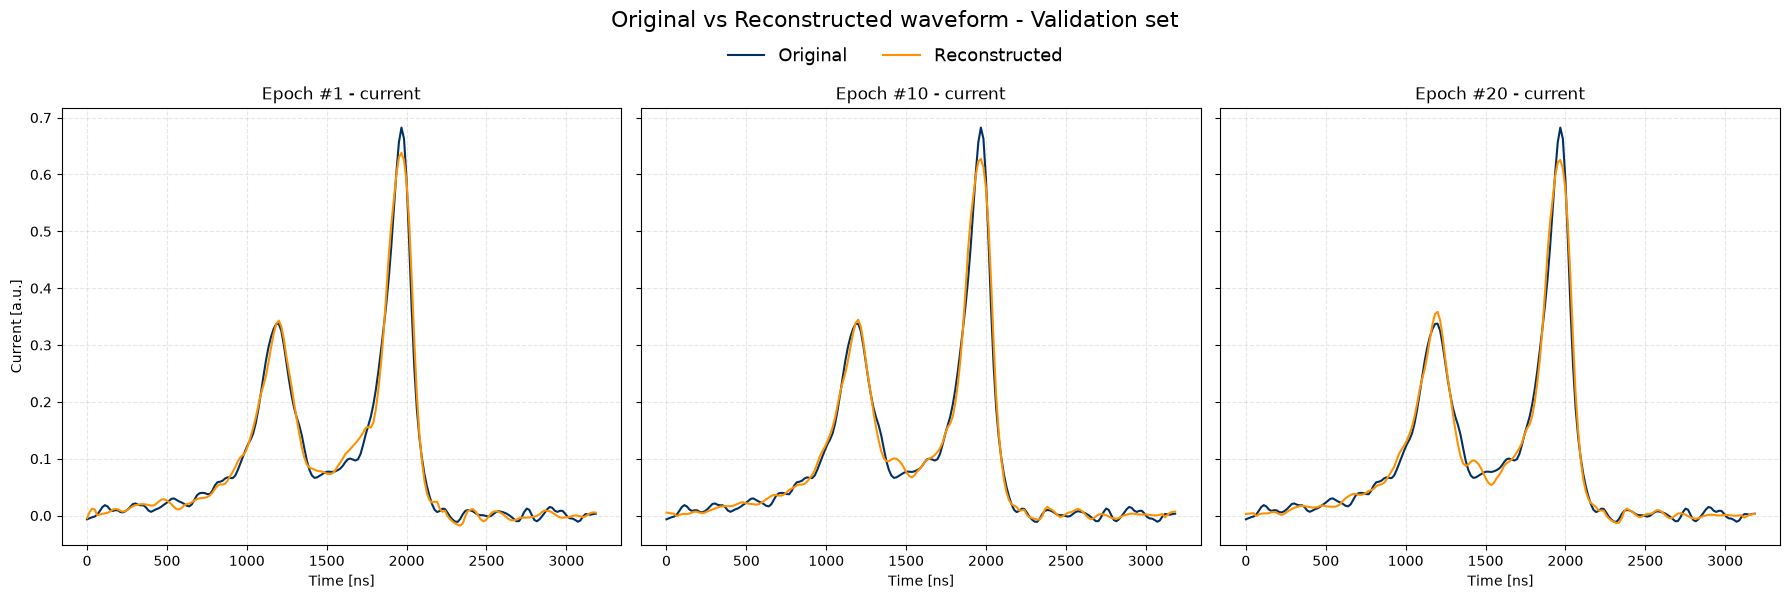

[euclidean, gamma=1000, 2 clusters] events that changed cluster with the training: 0.3568


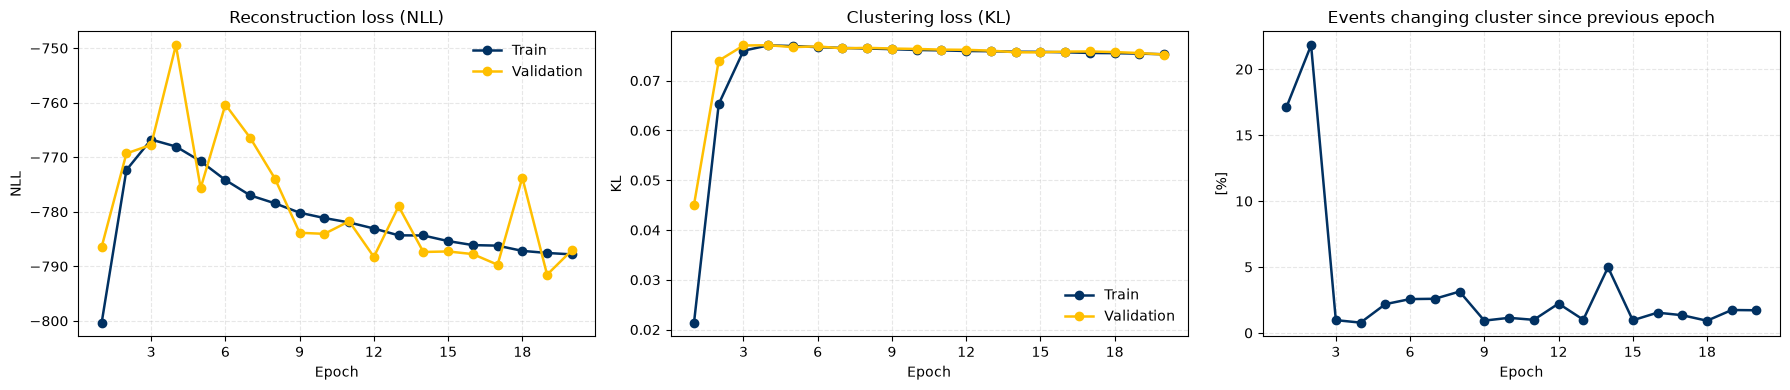

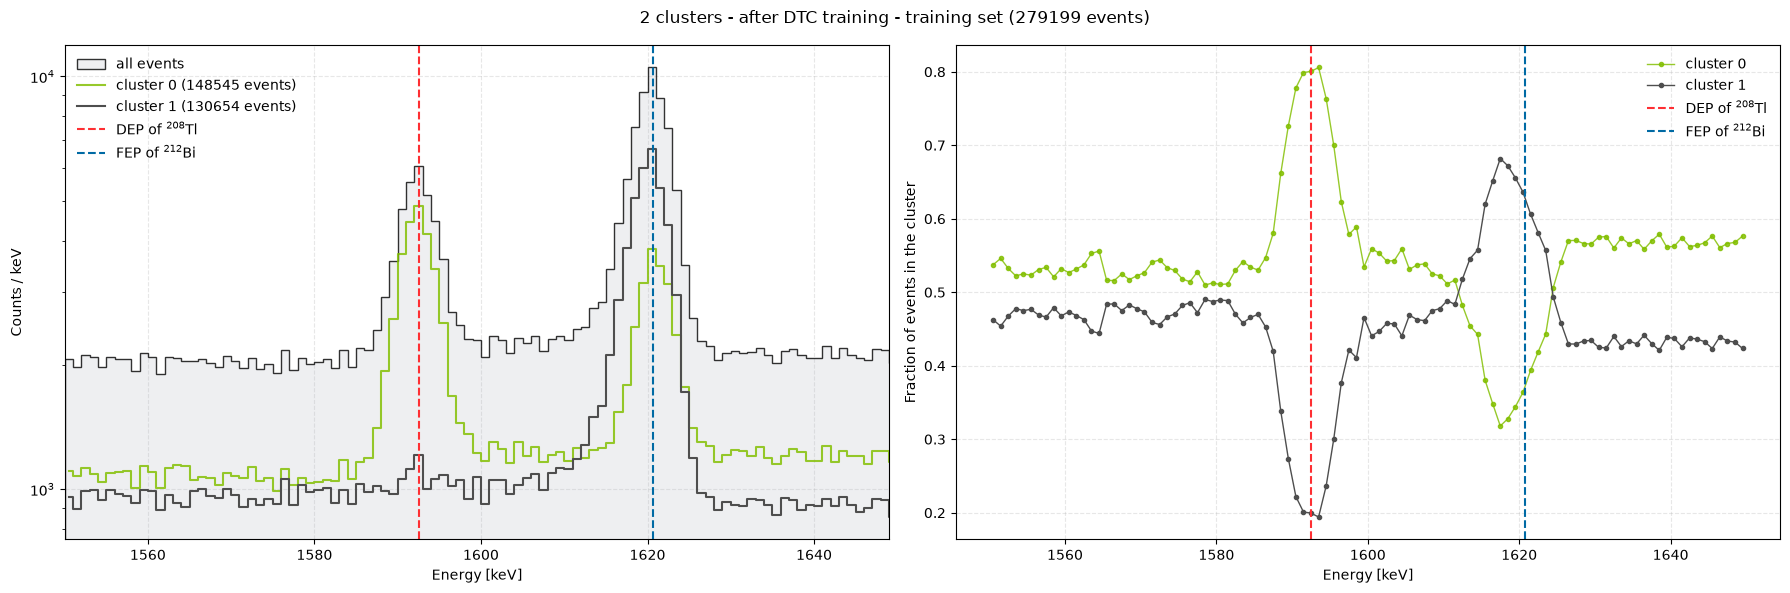

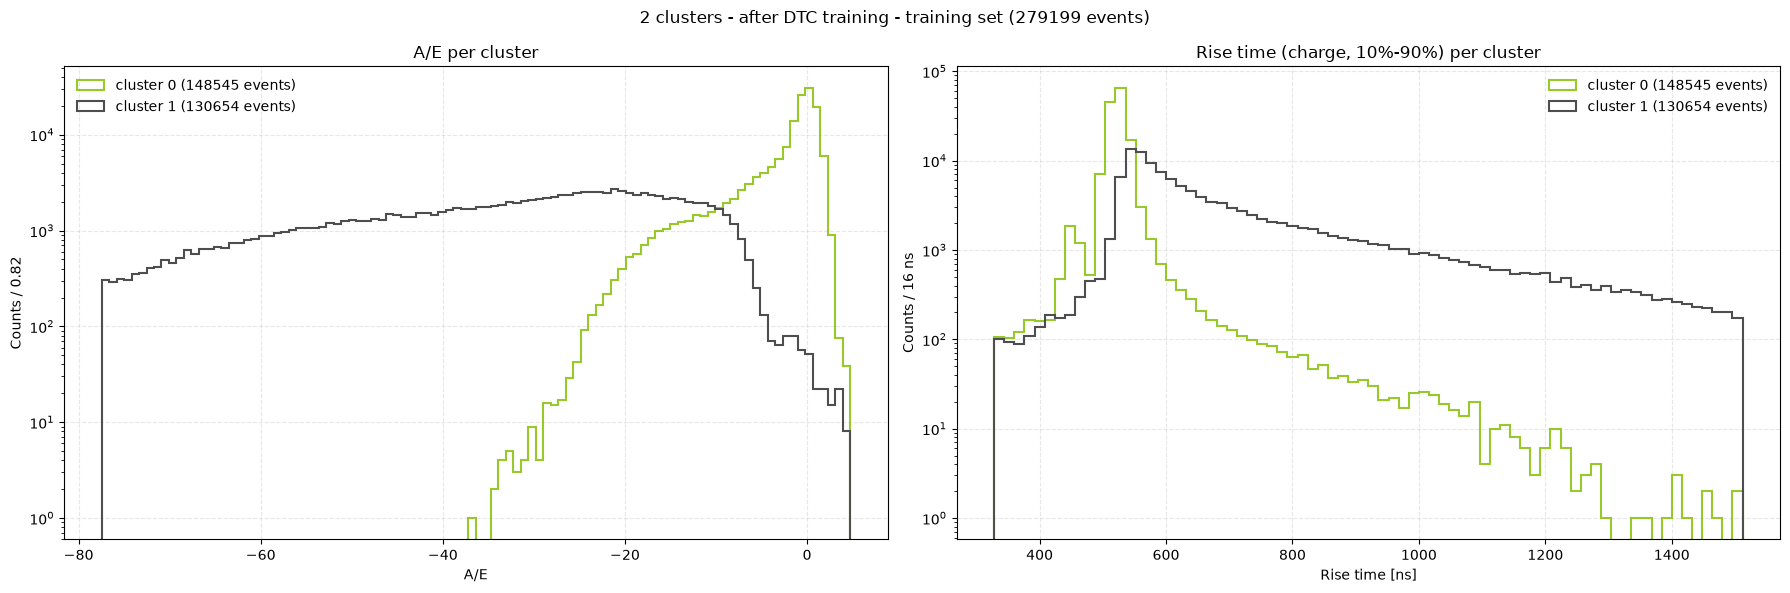

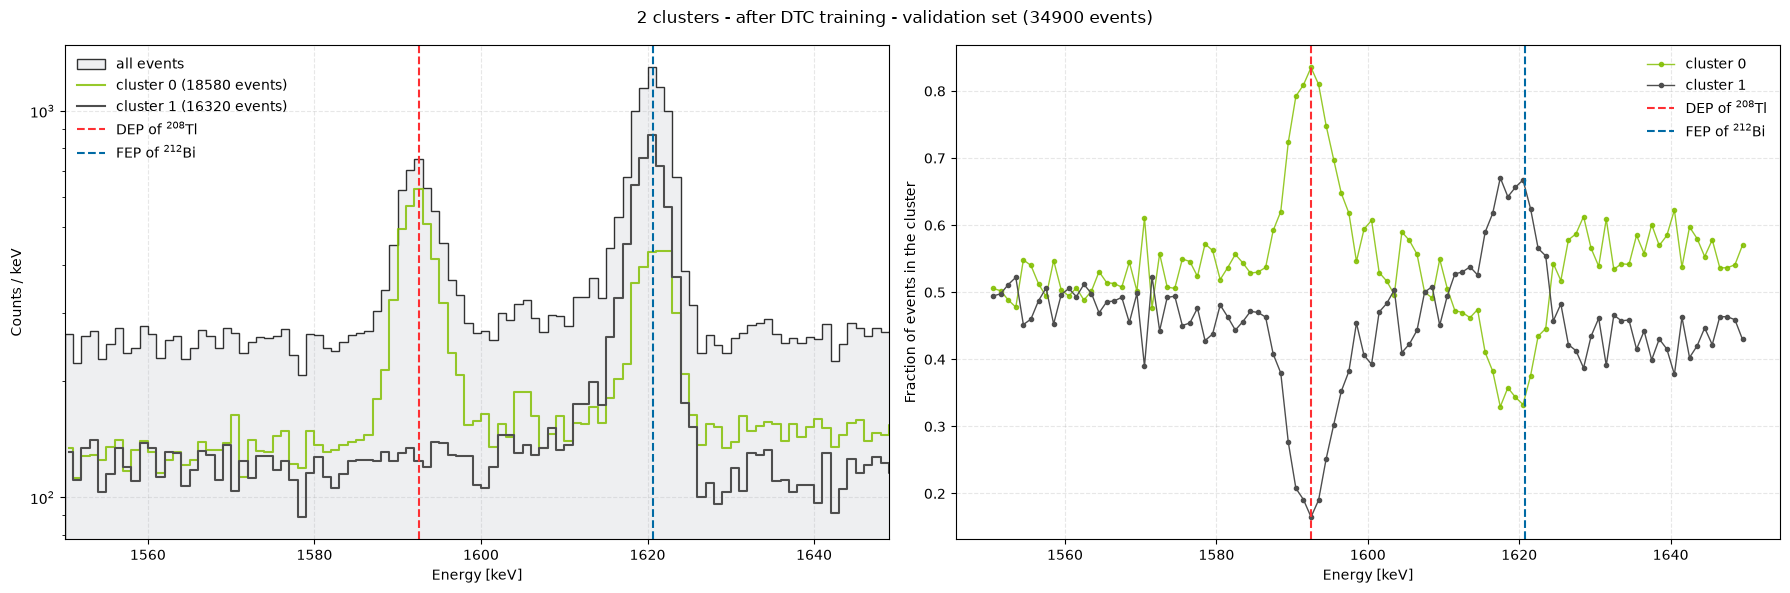

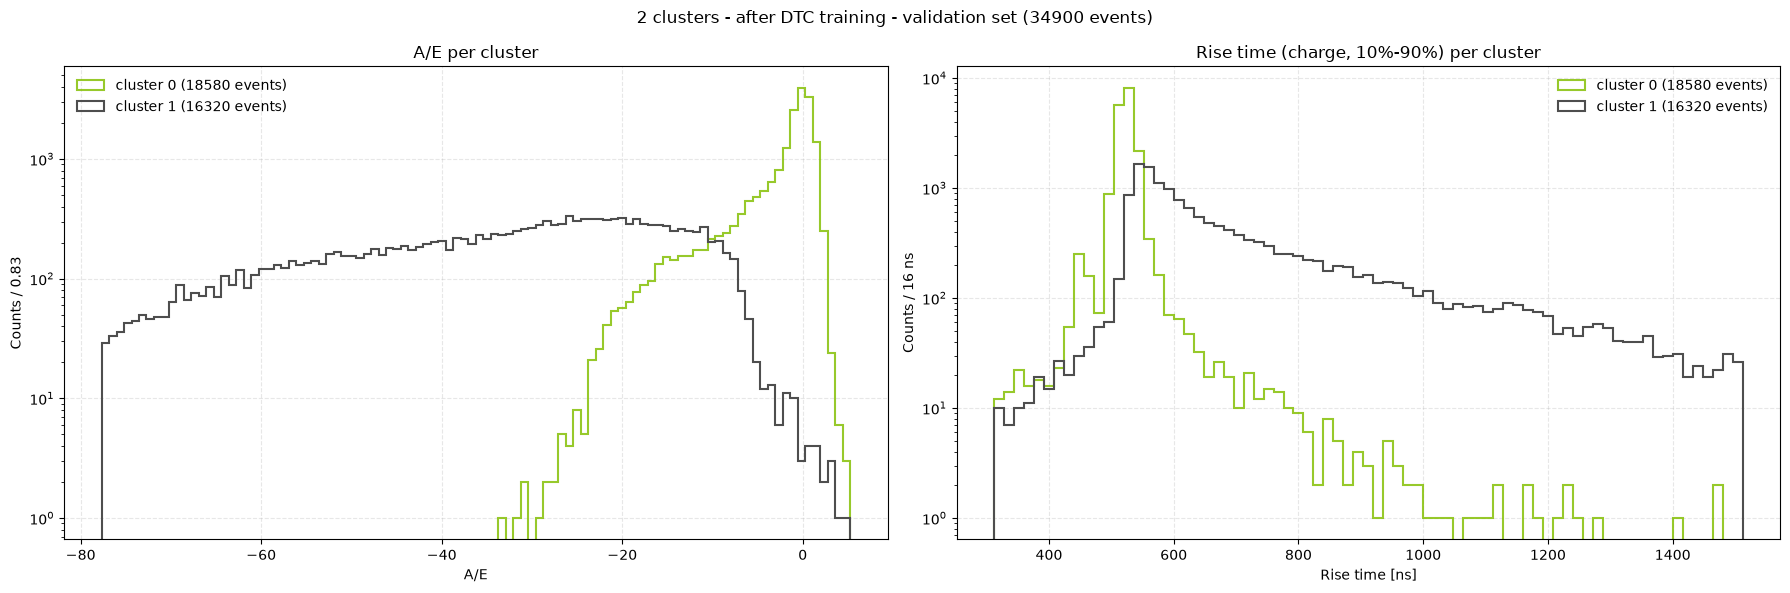

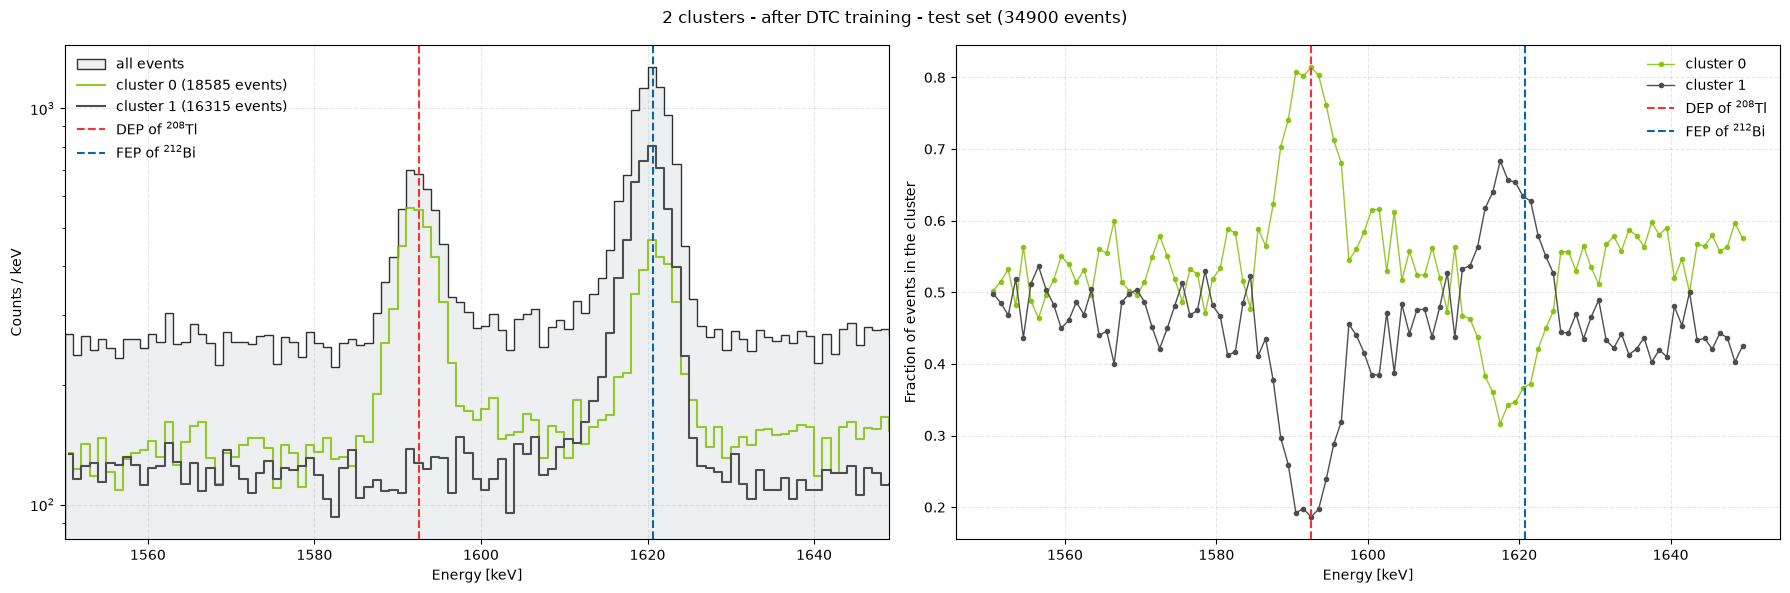

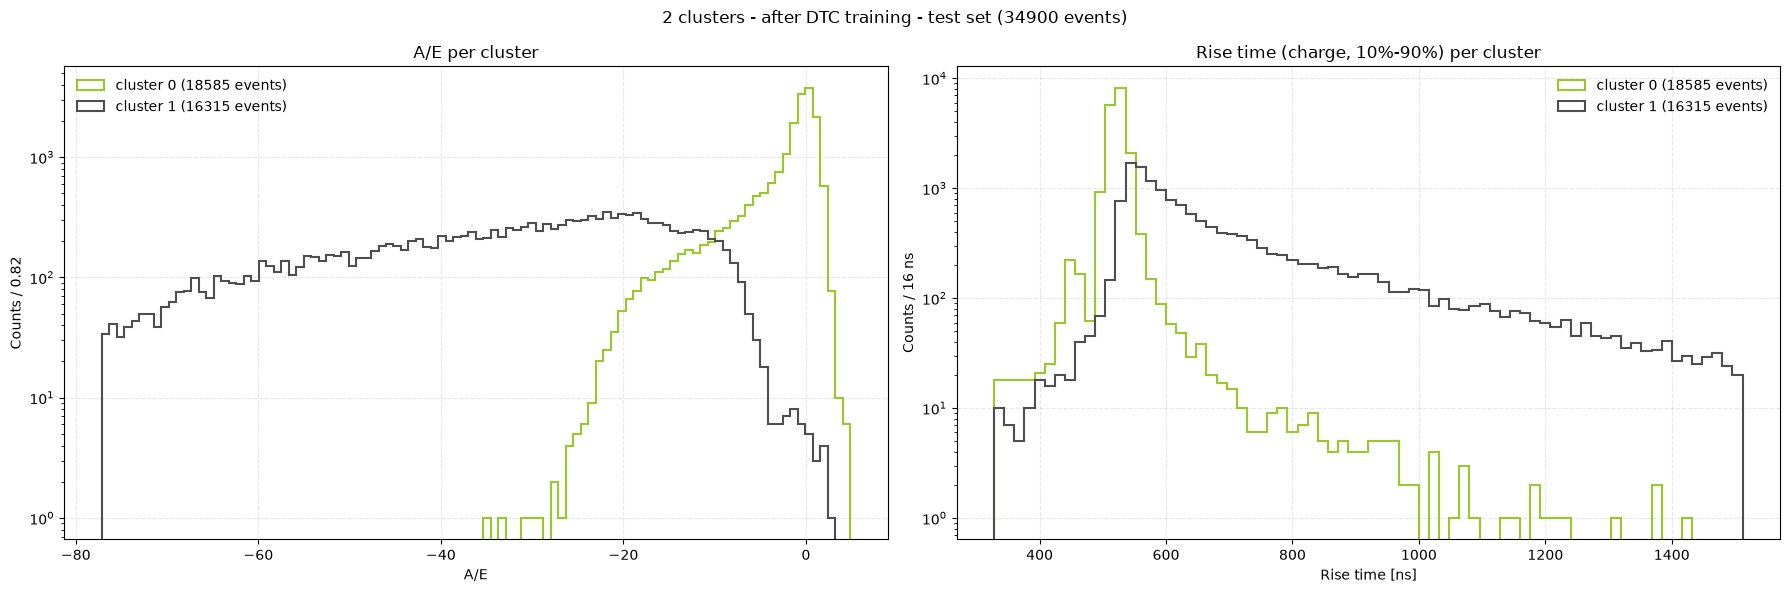

,total train,total validation,NLL train,NLL validation,KL train,KL validation,changes [%],events per cluster
epoch,,,,,,,,
1,-778.92,-741.36,-800.32,-786.44,0.02,0.05,17.09,0.72/0.28
2,-707.04,-695.29,-772.34,-769.31,0.07,0.07,21.82,0.50/0.50
3,-690.75,-690.66,-766.76,-767.72,0.08,0.08,0.97,0.51/0.49
4,-690.95,-672.34,-768.04,-749.46,0.08,0.08,0.78,0.50/0.50
5,-693.79,-698.92,-770.74,-775.66,0.08,0.08,2.18,0.48/0.52
6,-697.45,-683.47,-774.18,-760.35,0.08,0.08,2.57,0.50/0.50
7,-700.43,-689.94,-776.99,-766.43,0.08,0.08,2.59,0.53/0.47
8,-701.99,-697.31,-778.45,-773.90,0.08,0.08,3.14,0.50/0.50
9,-703.84,-707.40,-780.17,-783.85,0.08,0.08,0.93,0.50/0.50


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_eucl_training_losses.csv | table_eucl_training_losses.tex
euclidean: DEP per cluster [0.724 0.276] | FEP per cluster [0.395 0.605] -> SSE-like cluster = 0
saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_euclidean_gamma1000_20ep.pth | /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_euclidean_gamma1000_20ep_bundle.pth


In [77]:
runs['eucl'] = run_final('eucl')

#### CID

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.907 0.093]
[train] epoch 1/20 - train: -730.5819  val: -734.8083  events per cluster: [0.507 0.493]  changes: 0.4000
        NLL: -771.12   KL: 0.0405
[train] epoch 2/20 - train: -745.4200  val: -755.0341  events per cluster: [0.505 0.495]  changes: 0.0083
        NLL: -771.15   KL: 0.0257
[train] epoch 3/20 - train: -754.4844  val: -760.9735  events per cluster: [0.506 0.494]  changes: 0.0044
        NLL: -774.59   KL: 0.0201
[train] epoch 4/20 - train: -760.2745  val: -763.7163  events per cluster: [0.47 0.53]  changes: 0.0370
        NLL: -777.36   KL: 0.0171
[train] epoch 5/20 - train: -763.9901  val: -769.7373  events per cluster: [0.508 0.492]  changes: 0.0384
        NLL: -779.26   KL: 0.0153
[train] epoch 6/20 - train: -768.1290  val: -767.1243  events per cluster: [0.562 0.438]  changes: 0.0546
       

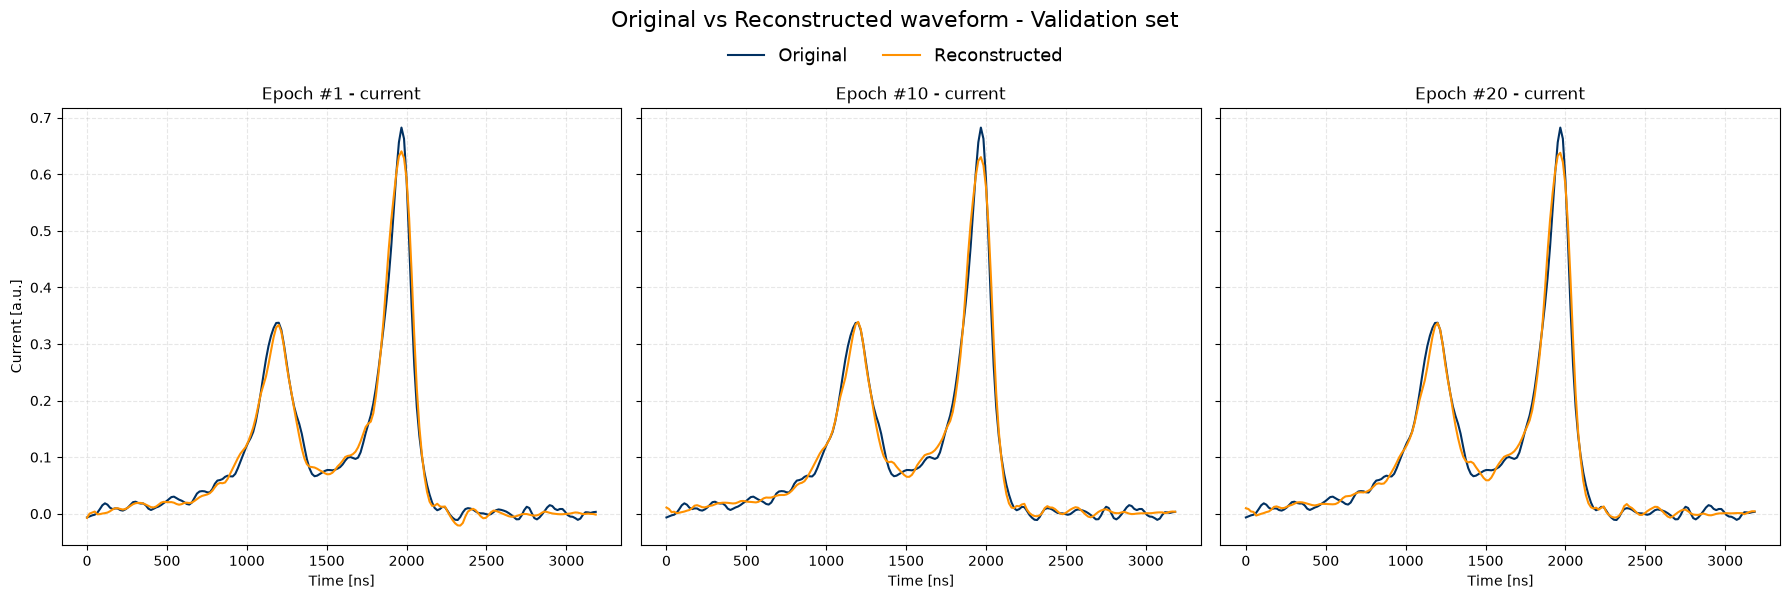

[cid, gamma=1000, 2 clusters] events that changed cluster with the training: 0.3882


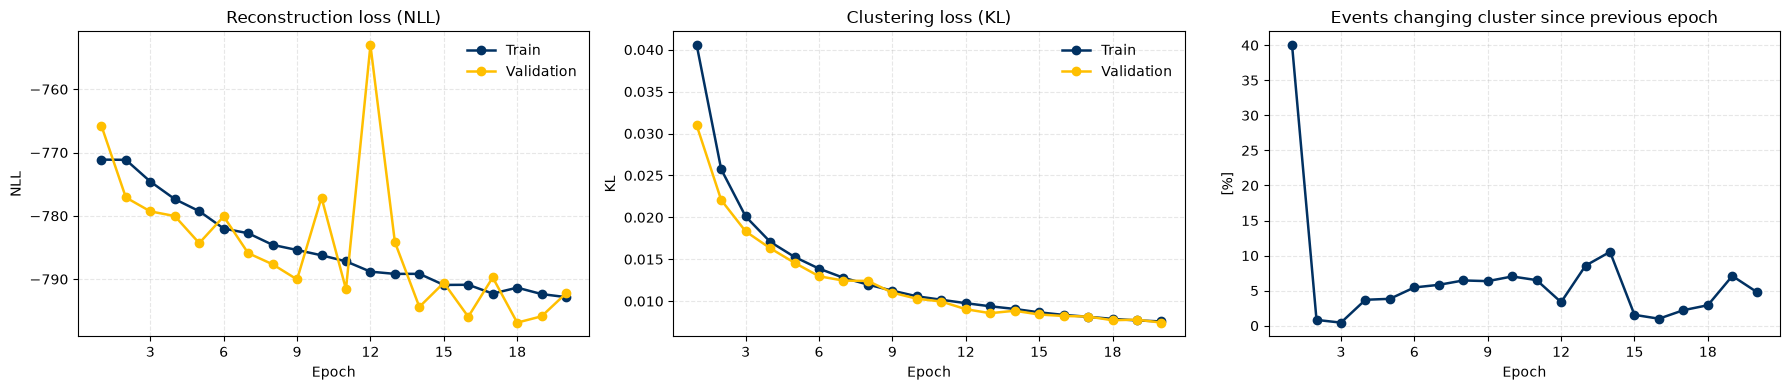

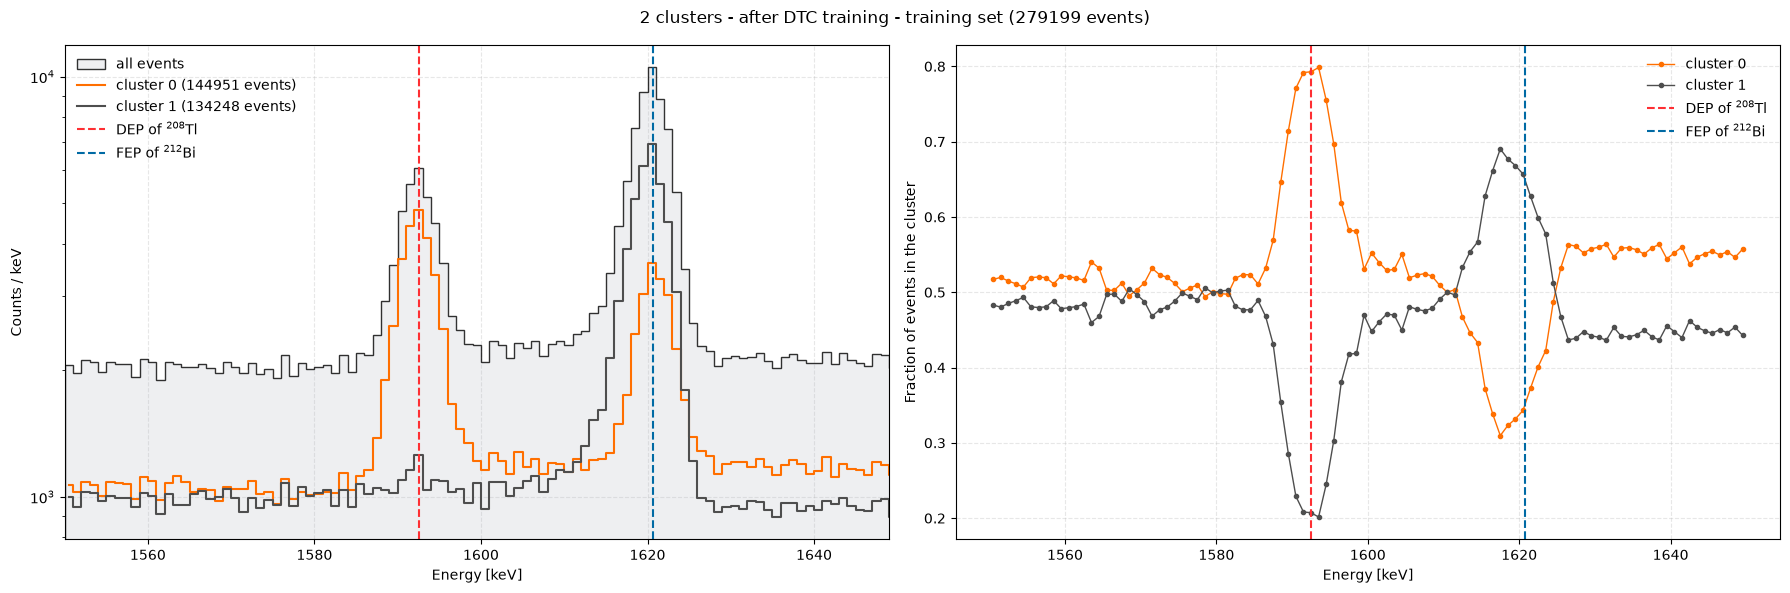

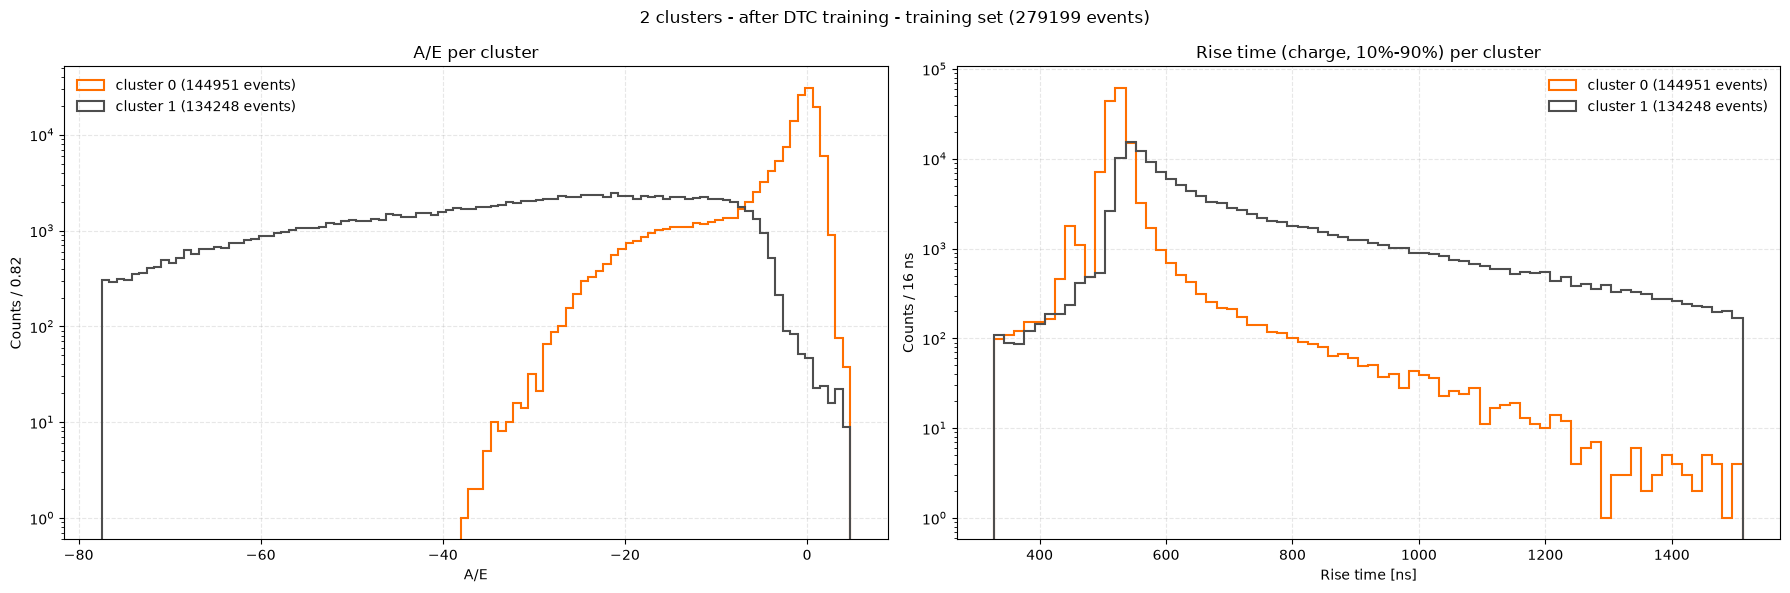

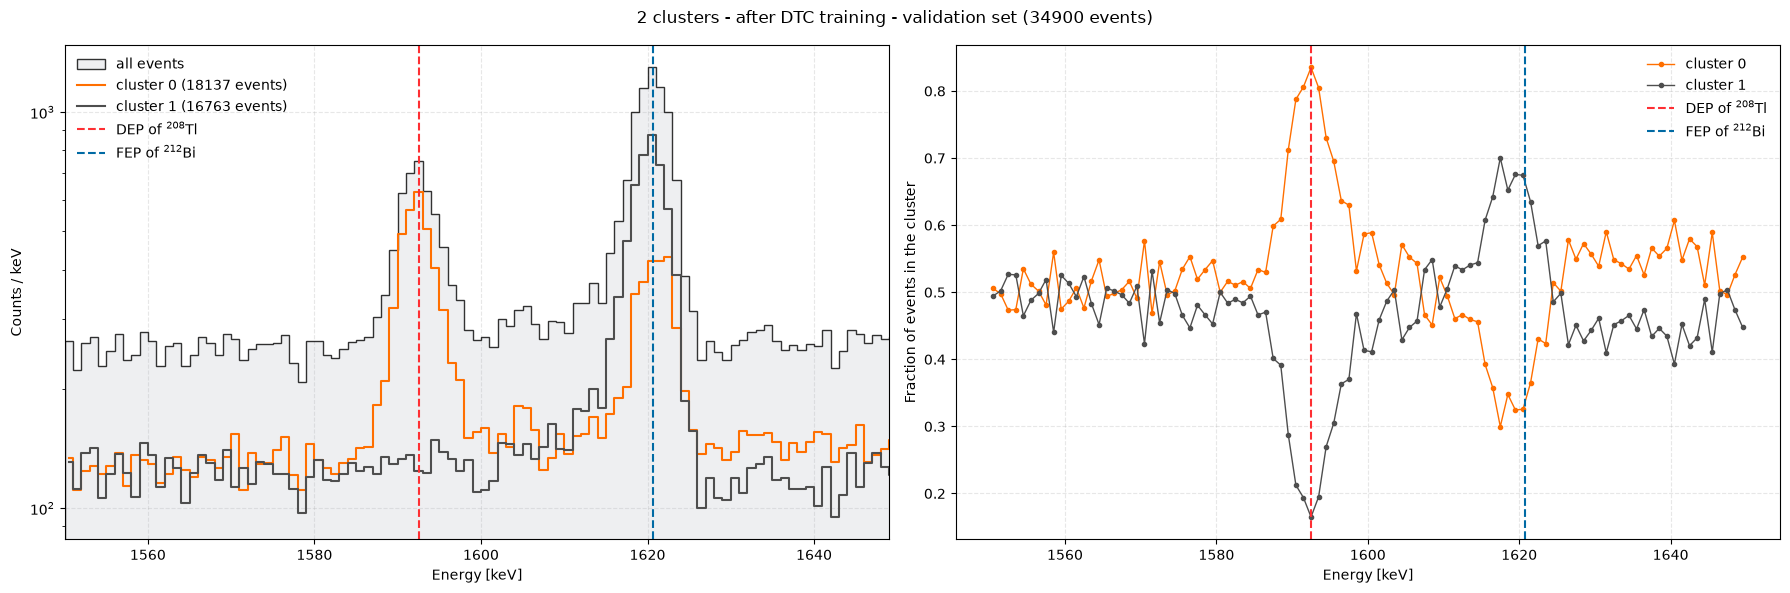

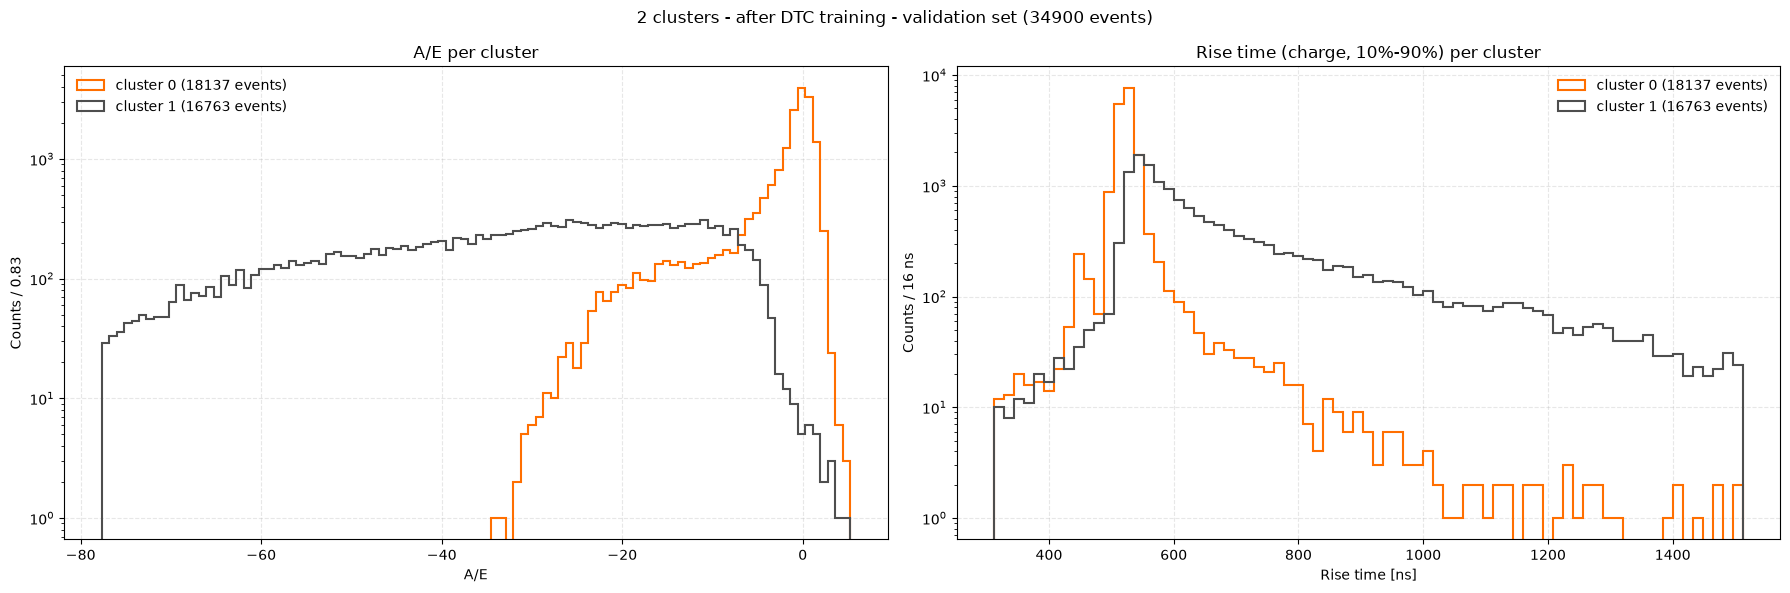

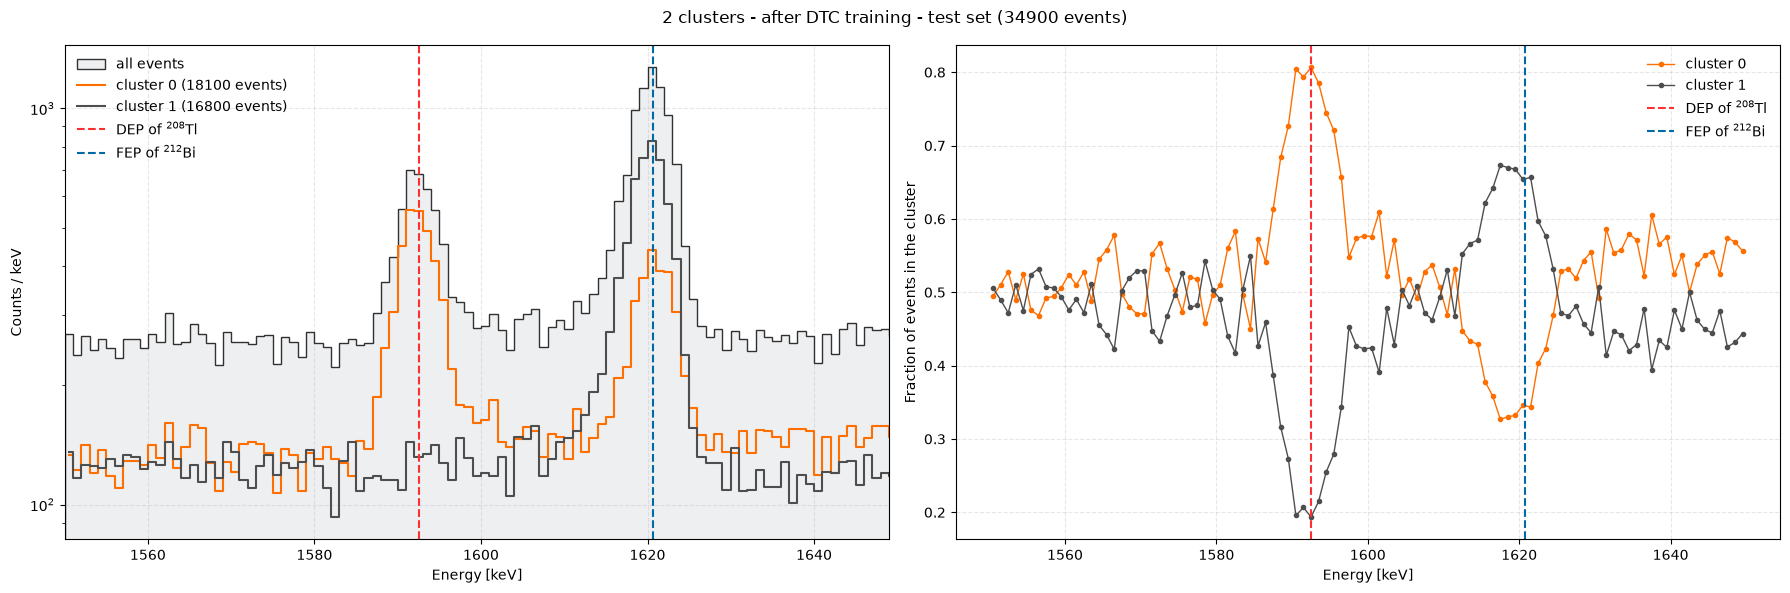

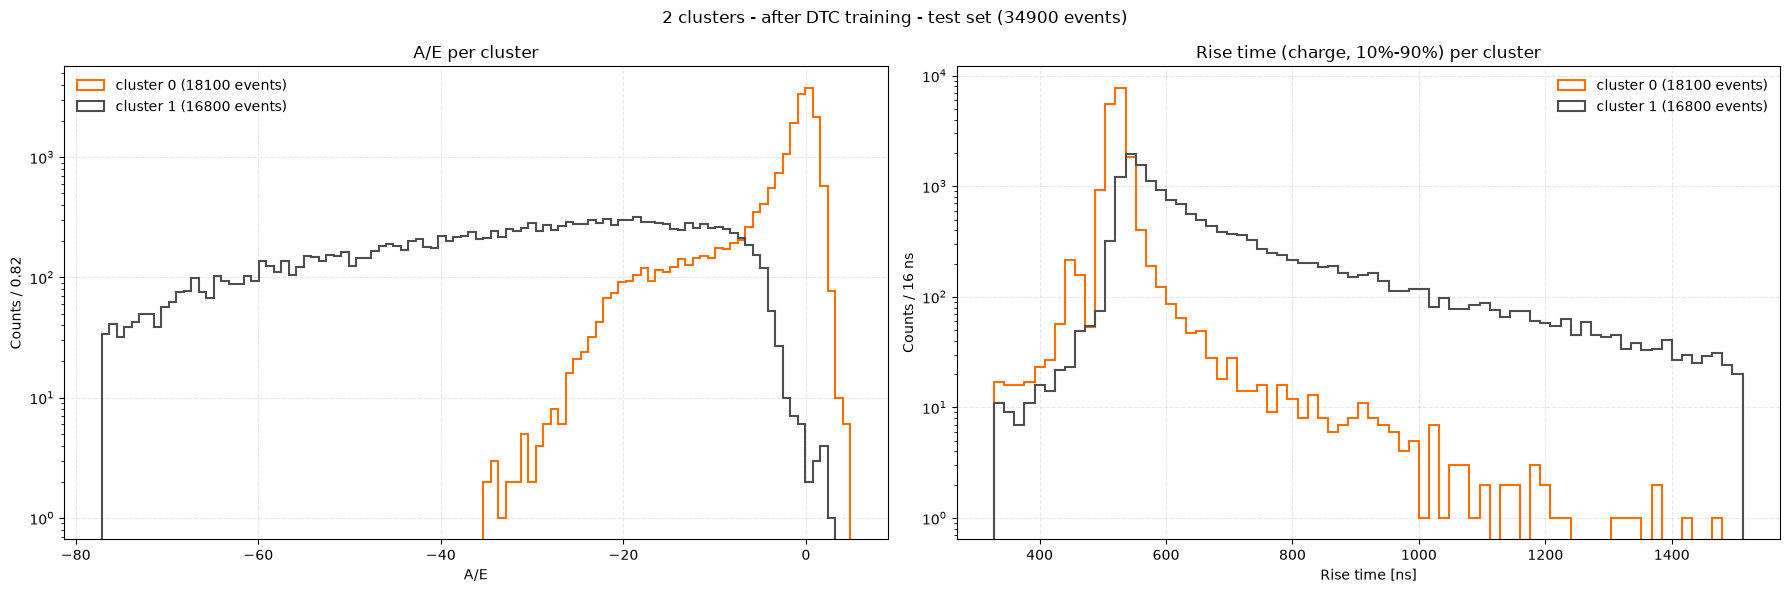

,total train,total validation,NLL train,NLL validation,KL train,KL validation,changes [%],events per cluster
epoch,,,,,,,,
1,-730.58,-734.81,-771.12,-765.76,0.04,0.03,40.00,0.51/0.49
2,-745.42,-755.03,-771.15,-777.10,0.03,0.02,0.83,0.51/0.49
3,-754.48,-760.97,-774.59,-779.29,0.02,0.02,0.44,0.51/0.49
4,-760.27,-763.72,-777.36,-780.03,0.02,0.02,3.70,0.47/0.53
5,-763.99,-769.74,-779.26,-784.31,0.02,0.01,3.84,0.51/0.49
6,-768.13,-767.12,-782.01,-780.09,0.01,0.01,5.46,0.56/0.44
7,-769.96,-773.44,-782.74,-785.89,0.01,0.01,5.83,0.50/0.50
8,-772.61,-775.24,-784.58,-787.66,0.01,0.01,6.46,0.44/0.56
9,-774.15,-779.04,-785.40,-790.05,0.01,0.01,6.36,0.50/0.50


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_cid_training_losses.csv | table_cid_training_losses.tex
cid: DEP per cluster [0.716 0.284] | FEP per cluster [0.381 0.619] -> SSE-like cluster = 0
saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_cid_gamma1000_20ep.pth | /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_cid_gamma1000_20ep_bundle.pth


In [78]:
runs['cid'] = run_final('cid')

# 4. COMPARISON OF THE METRICS
Fraction of events kept by each metric (= events in its SSE-like cluster), in total and in the DEP and FEP windows, on every set.
A/E is available only on the whole calibration dataset (the events after the A/E cut are cleaned as a separate set).
Raw counts in the windows, no background subtraction: the same for every row, so the rows are comparable.

In [79]:
split_names = {'train': 'training', 'val': 'validation', 'test': 'test', 'all': 'whole dataset'}
rows = []
for tag, r in runs.items():
    keep = r['y'] == r['sse_cluster']
    for split in ('train', 'val', 'test', 'all'):
        idx = np.arange(len(energy)) if split == 'all' else data[f'idx_{split}']
        k, d, f = keep[idx], in_dep[idx], in_fep[idx]
        rows.append({'cut / set': f"{NAMES[tag]} / {split_names[split]}",
                     'kept [%]': 100 * k.mean(), 'DEP kept [%]': 100 * k[d].mean(), 'FEP kept [%]': 100 * k[f].mean()})

e_all, e_aoe = clean['energy_all'], clean['energy_AoE_all']
win = lambda e, p: np.abs(e - p[1]) <= 3 * p[2]
rows.append({'cut / set': 'A/E / whole dataset',
             'kept [%]': 100 * len(e_aoe) / len(e_all),
             'DEP kept [%]': 100 * win(e_aoe, dep).sum() / win(e_all, dep).sum(),
             'FEP kept [%]': 100 * win(e_aoe, fep).sum() / win(e_all, fep).sum()})
save_table(pd.DataFrame(rows).set_index('cut / set'), 'table_metrics_comparison')

,kept [%],DEP kept [%],FEP kept [%]
cut / set,,,
ACF / training,47.26,68.36,32.34
ACF / validation,47.38,69.10,32.62
ACF / test,47.48,69.50,32.69
ACF / whole dataset,47.29,68.55,32.40
Euclidean / training,53.20,72.22,39.44
Euclidean / validation,53.24,72.70,39.80
Euclidean / test,53.25,73.21,39.39
Euclidean / whole dataset,53.21,72.37,39.47
CID / training,51.92,71.47,38.04


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_metrics_comparison.csv | table_metrics_comparison.tex
